# Fraud Detection & Diabetes Prediction with MLflow Experiment Tracking
**Machine Learning coursework, The British University in Egypt, 2026. Author: Ziad Ayman**

Leakage-safe scikit-learn pipelines on two datasets: ~300K online payments (2.2% fraud) and Pima Indians Diabetes (768 rows).
Covers EDA, K-Means cluster features, baselines vs. ensembles, a learning-curve bias–variance check, resampling (SMOTE, over- and under-sampling) and **MLflow** tracking of every run.

**Best result (payments):** bagging, 0.83 F1 · 0.975 ROC-AUC · 0.95 precision.

> Place `data/transactions.csv` and `data/diabetes.csv` next to this notebook (not included). Run `mlflow ui` to browse experiments.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset 1 — Fraud Detection

## Data Loading and Quick Checks


In [3]:
# Load Dataset 1 (Fraud Detection)
# NOTE: path fixed to a relative path so the notebook runs on any machine.
# Place transactions.csv in a "data" folder next to this notebook (see submitted zip).
df = pd.read_csv("data/transactions.csv")


In [4]:
df.head()

   transaction_id  user_id  account_age_days  total_transactions_user  \
0               1        1               141                       47   
1               2        1               141                       47   
2               3        1               141                       47   
3               4        1               141                       47   
4               5        1               141                       47   

   avg_amount_user  amount country bin_country channel merchant_category  \
0           147.93   84.75      FR          FR     web            travel   
1           147.93  107.90      FR          FR     web            travel   
2           147.93   92.36      FR          FR     app            travel   
3           147.93  112.47      FR          FR     web           fashion   
4           147.93  132.91      FR          US     web       electronics   

   promo_used  avs_match  cvv_result  three_ds_flag      transaction_time  \
0           0          1   

In [5]:
df.shape

(299695, 17)

In [6]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [7]:
# Missing values per column
df.isnull().sum()

transaction_id             0
user_id                    0
account_age_days           0
total_transactions_user    0
avg_amount_user            0
amount                     0
country                    0
bin_country                0
channel                    0
merchant_category          0
promo_used                 0
avs_match                  0
cvv_result                 0
three_ds_flag              0
transaction_time           0
shipping_distance_km       0
is_fraud                   0
dtype: int64

In [8]:
# Data types and memory
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  object 
 7   bin_country              299695 non-null  object 
 8   channel                  299695 non-null  object 
 9   merchant_category        299695 non-null  object 
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  tran

## Target Distribution 


In [9]:
# Set target column and basic counts
target_col = "is_fraud"

df[target_col].value_counts()


is_fraud
0    293083
1      6612
Name: count, dtype: int64

In [10]:
# Class balance (%)
df[target_col].value_counts(normalize=True) * 100


is_fraud
0    97.793757
1     2.206243
Name: proportion, dtype: float64

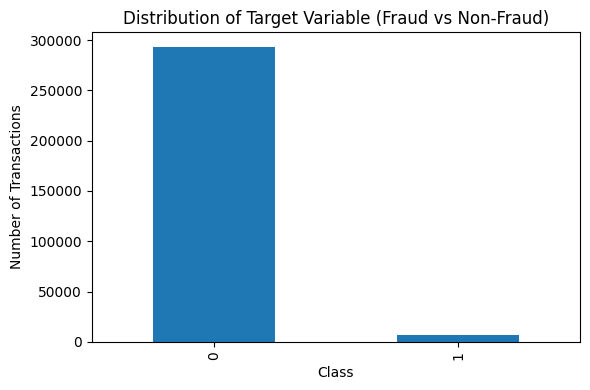

In [11]:
# Visualize class distribution
plt.figure(figsize=(6,4))
df[target_col].value_counts().plot(kind="bar")
plt.title("Distribution of Target Variable (Fraud vs Non-Fraud)")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


## Feature Engineering (Time and Flags)


In [12]:
# Parse timestamp
df["transaction_time"] = pd.to_datetime(
    df["transaction_time"],
    errors="coerce",
    utc=True
)

In [13]:
# Extract hour and day-of-week
df["hour"] = df["transaction_time"].dt.hour
df["dayofweek"] = df["transaction_time"].dt.dayofweek


In [14]:
# Quick check of derived columns
df[["transaction_time", "hour", "dayofweek"]].head()

           transaction_time  hour  dayofweek
0 2024-01-06 04:09:39+00:00     4          5
1 2024-01-09 20:13:47+00:00    20          1
2 2024-01-12 06:20:11+00:00     6          4
3 2024-01-15 17:00:04+00:00    17          0
4 2024-01-17 01:27:31+00:00     1          2

In [15]:
# Weekend flag
df["is_weekend"] = df["dayofweek"].isin([5, 6]).astype(int)


In [16]:
# Country vs BIN mismatch flag
df["country_mismatch"] = (df["country"] != df["bin_country"]).astype(int)


## Time-Based EDA


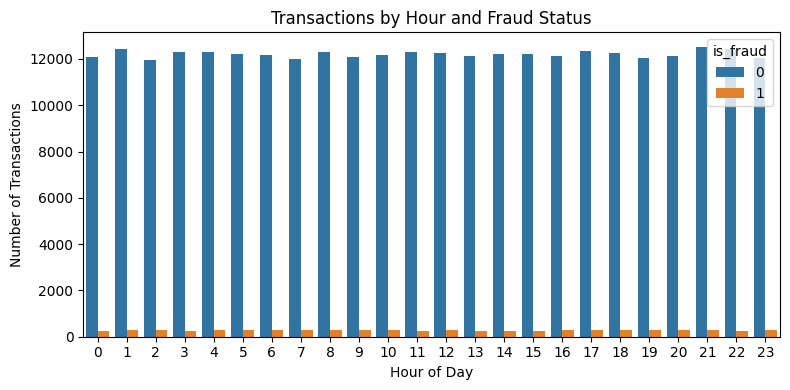

In [17]:
# Hourly transaction counts
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="hour", hue=target_col)
plt.title("Transactions by Hour and Fraud Status")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


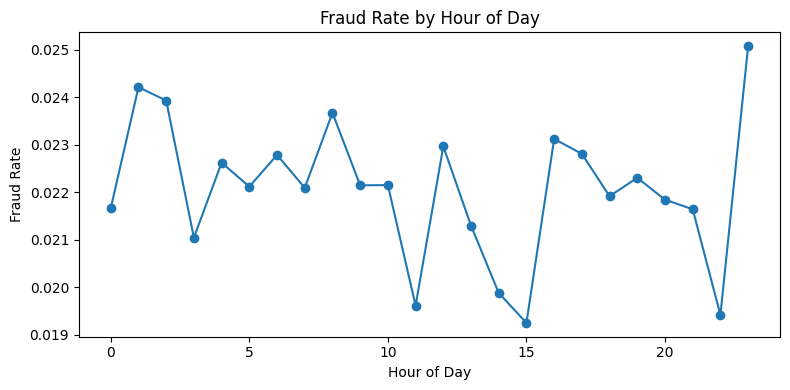

In [18]:
# Fraud rate by hour
hourly_fraud_rate = (
    df.groupby("hour")[target_col].mean()
)

plt.figure(figsize=(8,4))
hourly_fraud_rate.plot(kind="line", marker="o")
plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate")
plt.tight_layout()
plt.show()


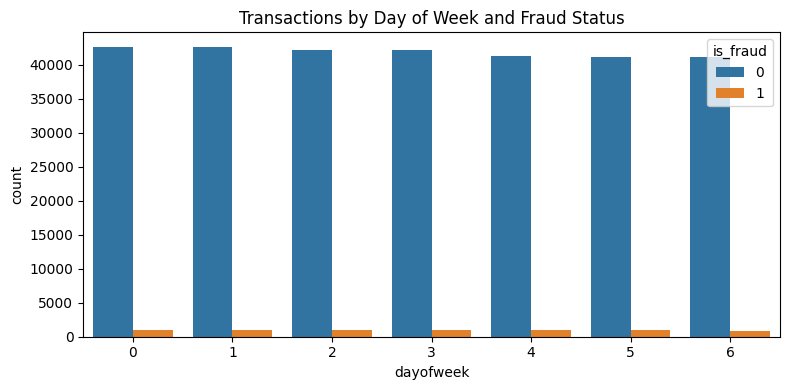

In [19]:
# Day-of-week counts
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="dayofweek", hue=target_col)
plt.title("Transactions by Day of Week and Fraud Status")
plt.tight_layout()
plt.show()


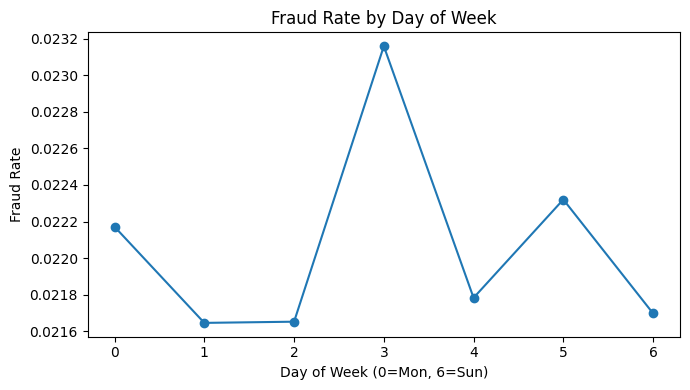

In [20]:
# Fraud rate by day-of-week
daily_fraud_rate = (
    df.groupby("dayofweek")[target_col]
    .mean()
)
plt.figure(figsize=(7,4))
daily_fraud_rate.plot(kind="line", marker="o")
plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day of Week (0=Mon, 6=Sun)")
plt.ylabel("Fraud Rate")
plt.tight_layout()
plt.show()


## Numeric EDA


In [21]:
# Identify numeric vs categorical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

numeric_cols, categorical_cols


(Index(['transaction_id', 'user_id', 'account_age_days',
        'total_transactions_user', 'avg_amount_user', 'amount', 'promo_used',
        'avs_match', 'cvv_result', 'three_ds_flag', 'shipping_distance_km',
        'is_fraud', 'is_weekend', 'country_mismatch'],
       dtype='object'),
 Index(['country', 'bin_country', 'channel', 'merchant_category'], dtype='object'))

In [22]:
# Numeric summary stats (consider excluding IDs)
df[numeric_cols].describe()

       transaction_id        user_id  account_age_days  \
count     299695.0000  299695.000000     299695.000000   
mean      149848.0000    3002.559432        973.397871   
std        86514.6388    1732.309663        525.241409   
min            1.0000       1.000000          1.000000   
25%        74924.5000    1501.000000        516.000000   
50%       149848.0000    3007.000000        975.000000   
75%       224771.5000    4504.000000       1425.000000   
max       299695.0000    6000.000000       1890.000000   

       total_transactions_user  avg_amount_user         amount     promo_used  \
count            299695.000000    299695.000000  299695.000000  299695.000000   
mean                 50.673321       148.142973     177.165279       0.153640   
std                   5.976391       200.364624     306.926507       0.360603   
min                  40.000000         3.520000       1.000000       0.000000   
25%                  46.000000        46.190000      42.100000       0.0

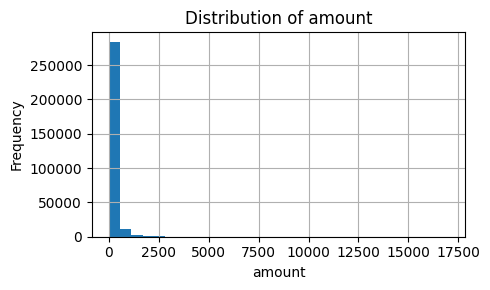

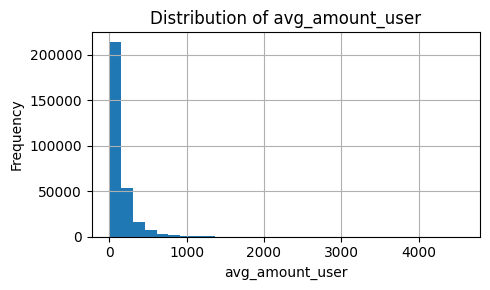

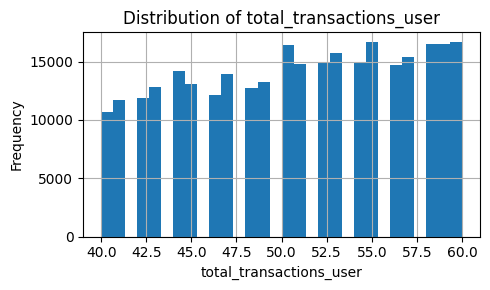

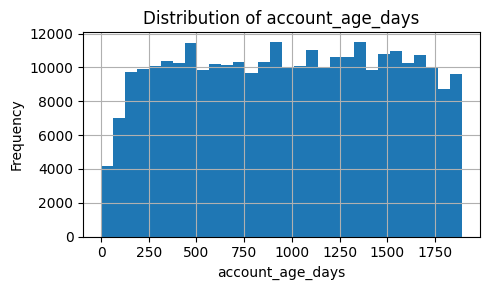

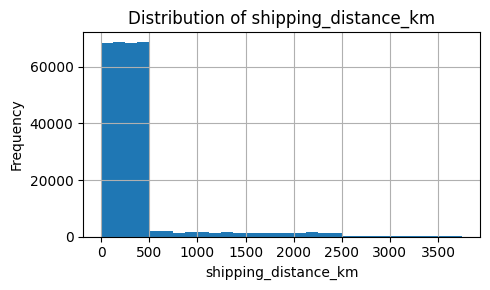

In [23]:
# Distributions of key numeric features
key_numeric = [
    "amount",
    "avg_amount_user",
    "total_transactions_user",
    "account_age_days",
    "shipping_distance_km"
]

for col in key_numeric:
    plt.figure(figsize=(5,3))
    df[col].hist(bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


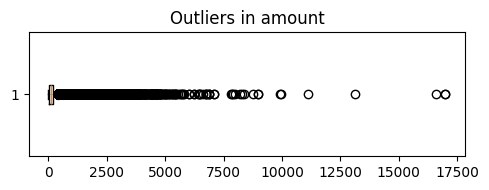

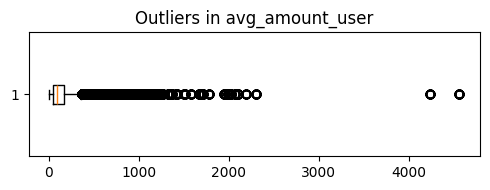

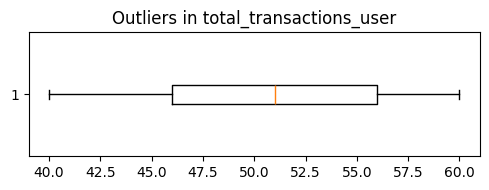

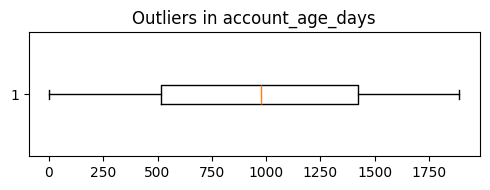

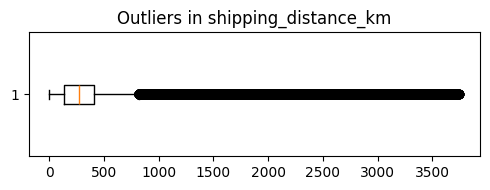

In [24]:
# Boxplots for outliers
for col in key_numeric:
    plt.figure(figsize=(5,2))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Outliers in {col}")
    plt.tight_layout()
    plt.show()

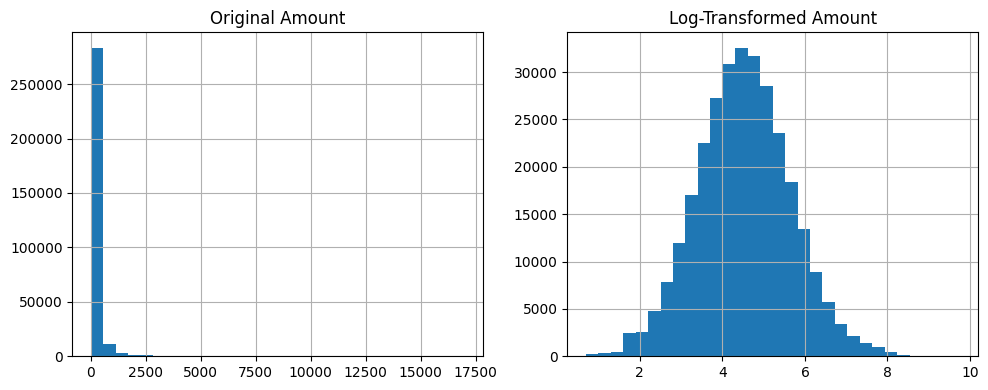

In [25]:
# Log-transform example for skewed feature
df["log_amount"] = np.log1p(df["amount"])

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
df["amount"].hist(bins=30)
plt.title("Original Amount")

plt.subplot(1,2,2)
df["log_amount"].hist(bins=30)
plt.title("Log-Transformed Amount")

plt.tight_layout()
plt.show()


In [26]:
# IQR-based outlier percentages
numeric_cols = df.select_dtypes(include="number").columns.tolist()
if target_col in numeric_cols:
    numeric_cols.remove(target_col)


def iqr_outlier_stats(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_pct = ((series < lower) | (series > upper)).mean() * 100
    return pd.Series({"iqr_lower": lower, "iqr_upper": upper, "outlier_pct": outlier_pct})

outlier_table = df[numeric_cols].apply(iqr_outlier_stats).T
outlier_table = outlier_table.sort_values("outlier_pct", ascending=False)
display(outlier_table)

                             iqr_lower      iqr_upper  outlier_pct
three_ds_flag                 1.000000       1.000000    21.541234
avs_match                     1.000000       1.000000    16.200137
promo_used                    0.000000       0.000000    15.363953
cvv_result                    1.000000       1.000000    12.789002
amount                     -181.415000     414.625000     8.912728
avg_amount_user            -144.700000     364.340000     7.971438
country_mismatch              0.000000       0.000000     7.918050
shipping_distance_km       -272.270000     818.050000     6.777557
log_amount                    1.521705       7.499886     0.981665
user_id                   -3003.500000    9008.500000     0.000000
account_age_days           -847.500000    2788.500000     0.000000
total_transactions_user      31.000000      71.000000     0.000000
transaction_id          -149846.000000  449542.000000     0.000000
hour                        -14.500000      37.500000     0.00

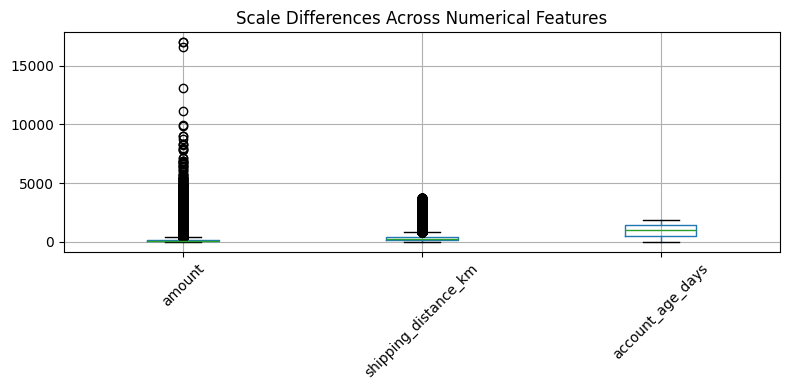

In [27]:
# Compare scales across numeric features
plt.figure(figsize=(8,4))
df[["amount", "shipping_distance_km", "account_age_days"]].boxplot()
plt.title("Scale Differences Across Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


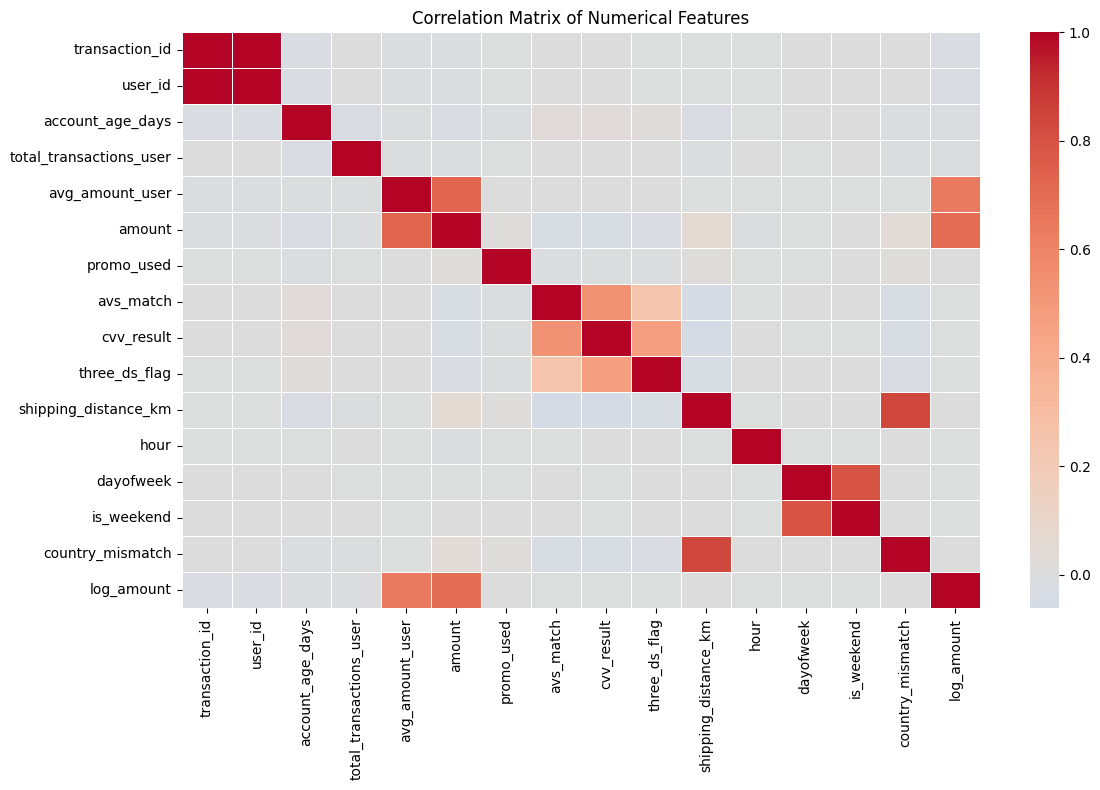

In [28]:
# Correlation heatmap (numeric)
plt.figure(figsize=(12,8))
corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


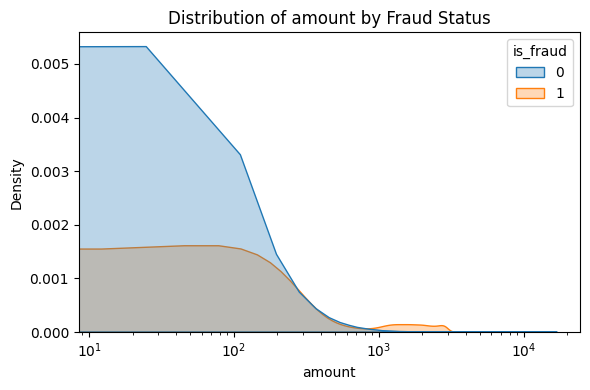

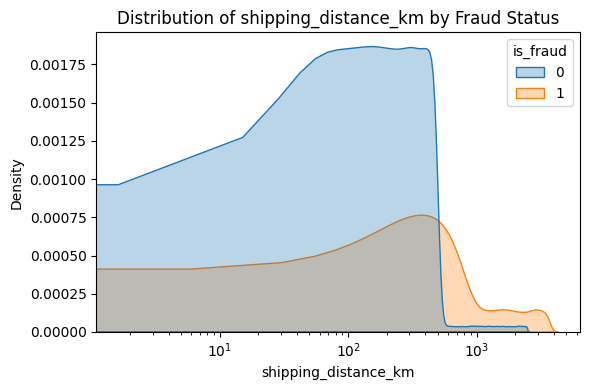

In [29]:
for col in ["amount", "shipping_distance_km"]:
    plt.figure(figsize=(6, 4))
    sns.kdeplot(
        data=df,
        x=col,
        hue=target_col,
        fill=True,
        common_norm=False,
        alpha=0.3
    )
    plt.title(f"Distribution of {col} by Fraud Status")
    plt.xscale("log")  
    plt.tight_layout()
    plt.show()


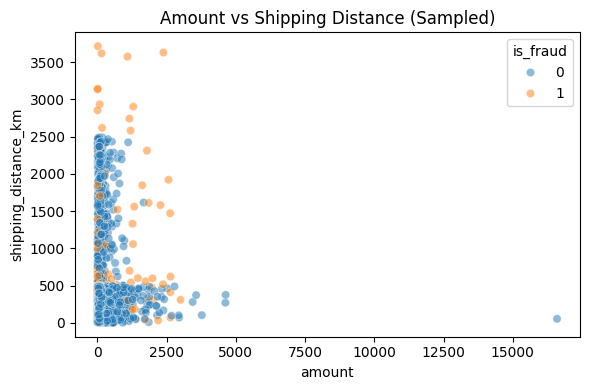

In [30]:
# Scatter of key numeric features (sample)
plt.figure(figsize=(6,4))
sns.scatterplot(
    data=df.sample(5000),
    x="amount",
    y="shipping_distance_km",
    hue=target_col,
    alpha=0.5
)
plt.title("Amount vs Shipping Distance (Sampled)")
plt.tight_layout()
plt.show()


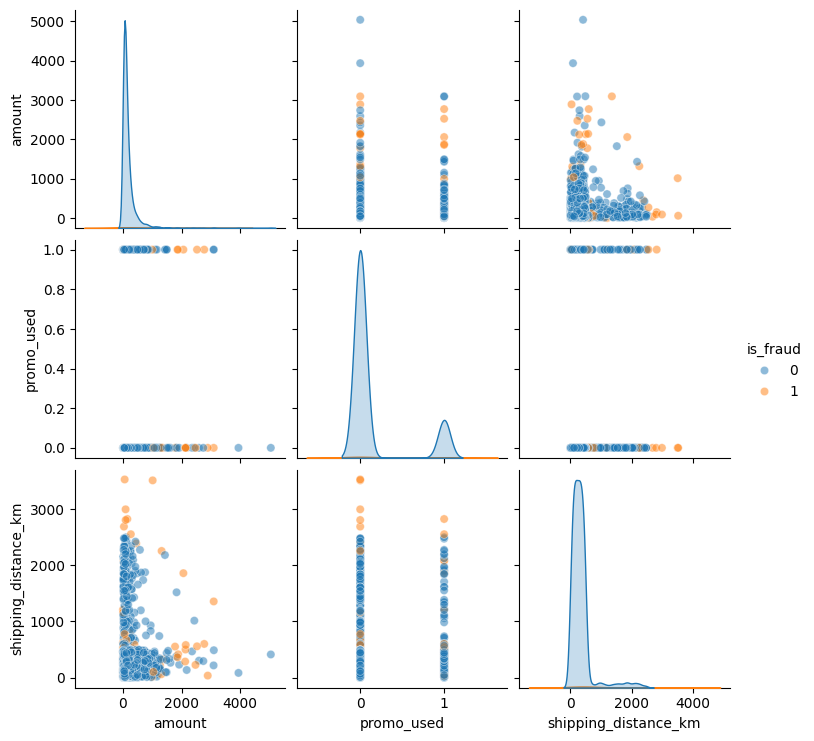

In [31]:
# Pairplot (sampled for performance — a pairplot on all 300k rows is not readable
# and is extremely slow; a random sample preserves the same visual relationships)
pair_features = [
    "amount",
    "promo_used",
    "shipping_distance_km",
    target_col
]

sns.pairplot(
    df[pair_features].sample(3000, random_state=34),
    hue=target_col,
    diag_kind="kde",
    plot_kws={"alpha": 0.5}
)
plt.show()


## Categorical and Binary EDA


In [32]:
# Fraud rate by binary flags
binary_features = [
    "promo_used",
    "avs_match",
    "cvv_result",
    "three_ds_flag"
]

for col in binary_features:
    fraud_rate = pd.crosstab(df[col], df[target_col], normalize="index")
    print(f"\nFraud rate by {col}")
    display(fraud_rate)



Fraud rate by promo_used


is_fraud           0         1
promo_used                    
0           0.982153  0.017847
1           0.954718  0.045282


Fraud rate by avs_match


is_fraud          0         1
avs_match                    
0          0.903339  0.096661
1          0.992359  0.007641


Fraud rate by cvv_result


is_fraud           0         1
cvv_result                    
0           0.893942  0.106058
1           0.990255  0.009745


Fraud rate by three_ds_flag


is_fraud              0         1
three_ds_flag                    
0              0.932479  0.067521
1              0.990418  0.009582

In [33]:
# Fraud rate by weekend flag
pd.crosstab(df["is_weekend"], df[target_col], normalize="index")


is_fraud           0         1
is_weekend                    
0           0.977917  0.022083
1           0.977991  0.022009

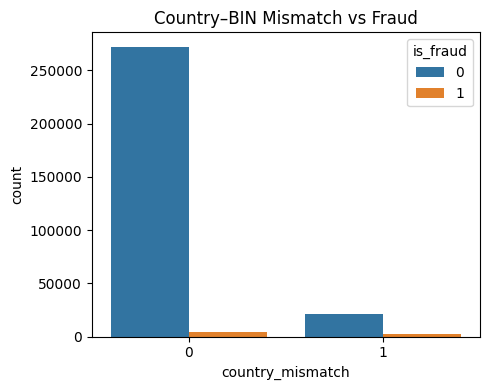

In [34]:
# Country mismatch vs fraud
plt.figure(figsize=(5,4))
sns.countplot(data=df, x="country_mismatch", hue=target_col)
plt.title("Country–BIN Mismatch vs Fraud")
plt.tight_layout()
plt.show()

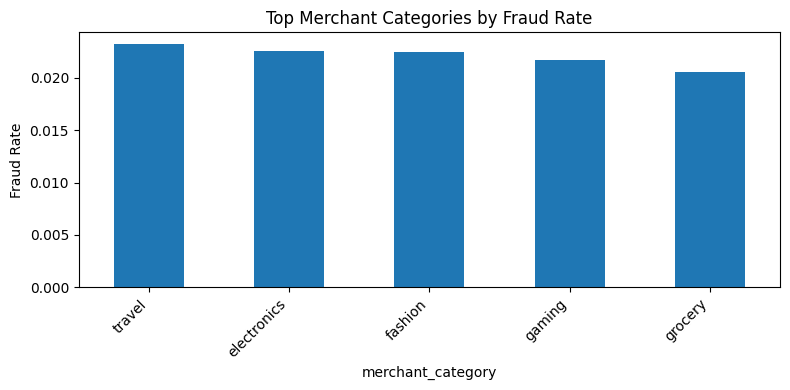

In [35]:
# Merchant categories with highest fraud rate
merchant_fraud_rate = (
    df.groupby("merchant_category")[target_col]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,4))
merchant_fraud_rate.head(10).plot(kind="bar")
plt.title("Top Merchant Categories by Fraud Rate")
plt.ylabel("Fraud Rate")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


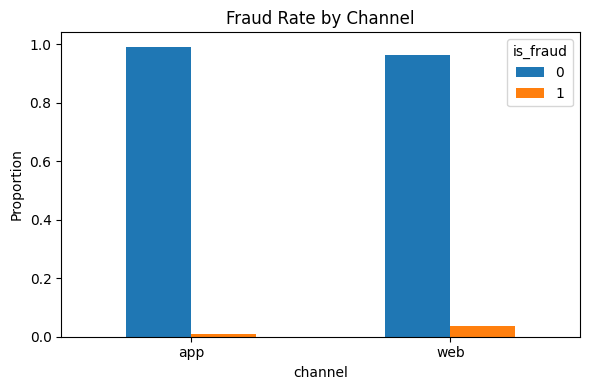

In [36]:
# Fraud rate by channel
channel_fraud = pd.crosstab(
    df["channel"],
    df[target_col],
    normalize="index"
)

channel_fraud.plot(kind="bar", figsize=(6,4))
plt.title("Fraud Rate by Channel")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


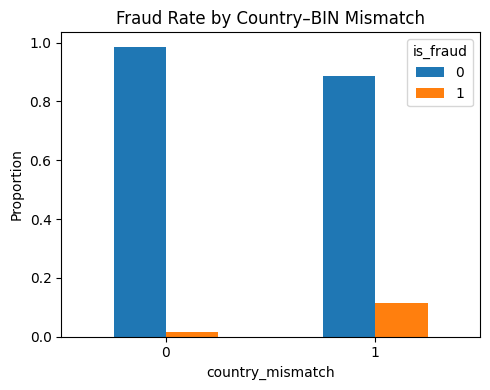

In [37]:
# Fraud rate by mismatch flag
mismatch_fraud = pd.crosstab(
    df["country_mismatch"],
    df[target_col],
    normalize="index"
)

mismatch_fraud.plot(kind="bar", figsize=(5,4))
plt.title("Fraud Rate by Country–BIN Mismatch")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [38]:
# Crosstab details (mismatch)
pd.crosstab(
    df["country_mismatch"],
    df[target_col],
    normalize="index"
)


is_fraud                 0         1
country_mismatch                    
0                 0.985737  0.014263
1                 0.887231  0.112769

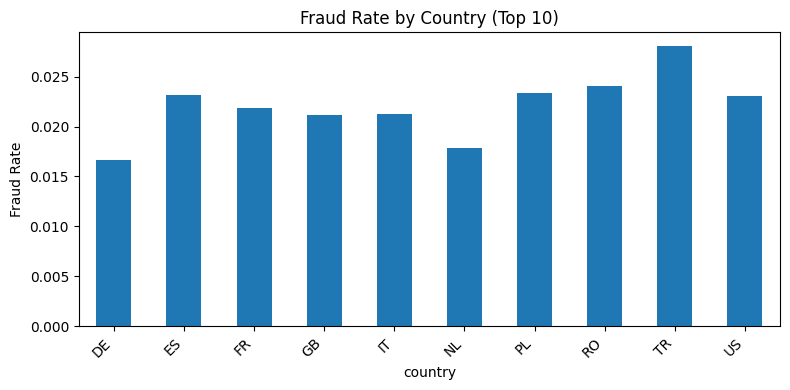

In [39]:
# Fraud rate by top countries
top_countries = df["country"].value_counts().head(10).index

country_fraud = (
    df[df["country"].isin(top_countries)]
    .groupby("country")[target_col]
    .mean()
)

plt.figure(figsize=(8,4))
country_fraud.plot(kind="bar")
plt.title("Fraud Rate by Country (Top 10)")
plt.ylabel("Fraud Rate")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


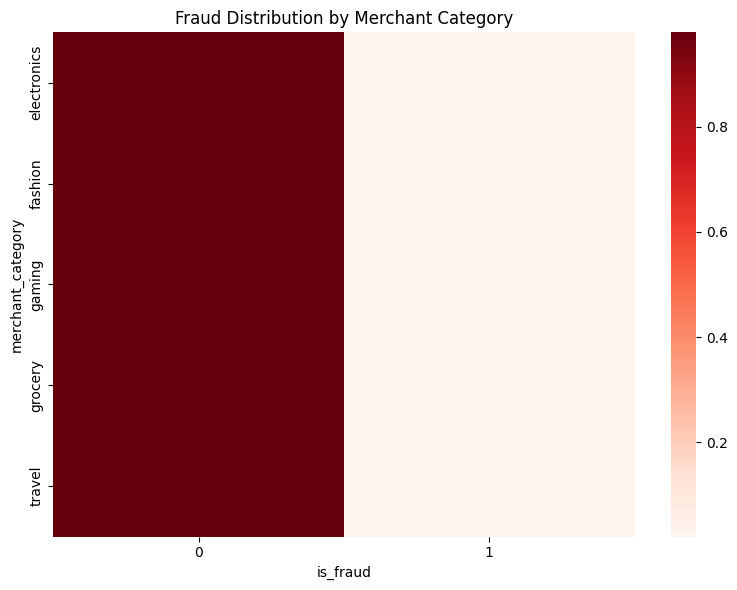

In [40]:
# Merchant category heatmap
merchant_fraud_matrix = pd.crosstab(
    df["merchant_category"],
    df[target_col],
    normalize="index"
)

plt.figure(figsize=(8,6))
sns.heatmap(
    merchant_fraud_matrix,
    cmap="Reds",
    cbar=True
)
plt.title("Fraud Distribution by Merchant Category")
plt.tight_layout()
plt.show()


## EDA Observations

**Skewed numeric features / outliers**
- `amount` and `avg_amount_user` are strongly right-skewed (skewness ≈ 8.3 and 6.5), and the IQR rule
  flags roughly **9%** of transactions as amount outliers and **8%** as outliers on `avg_amount_user`.
  `shipping_distance_km` is also right-skewed (skewness ≈ 3.5, ~7% IQR outliers). These are genuine
  large-but-legitimate transactions/shipments (long tails), not data errors, so we keep them and rely on
  `StandardScaler` + tree-based models (which are not sensitive to skew) rather than removing them.
- `total_transactions_user` and `account_age_days` are close to symmetric (skewness ≈ −0.1), so no
  transform is needed there.
- The binary flags (`promo_used`, `avs_match`, `cvv_result`, `three_ds_flag`) and the engineered
  `country_mismatch` flag show a high "outlier %" under the IQR rule, but that is an artefact of IQR
  being applied to 0/1 columns, not a real outlier signal — this is expected and can be ignored for
  binary features.

**Time-based trends**
- Fraud rate by hour of day is essentially flat, ranging only from ≈1.9% (hour 15) to ≈2.5% (hour 23) —
  there is **no strong hour-of-day pattern**.
- Fraud rate by day of week is similarly flat (≈2.16%–2.32% across all seven days), and the weekend vs.
  weekday fraud rate is almost identical (2.20% vs 2.21%). `hour` and `dayofweek` therefore carry weak
  signal individually but are kept as low-cost engineered features for the models to combine with others.

**Categorical / flag groups with higher fraud rates**
- `country_mismatch` is the strongest signal found in the EDA: fraud rate is **11.3%** when the
  cardholder country differs from the card BIN country, versus **1.4%** when they match — an ~8x
  difference.
- Failed verification checks are strongly associated with fraud: fraud rate is **9.7%** when
  `cvv_result` fails vs **1.0%** when it passes, **9.0%** for `avs_match` failing vs **0.8%** passing, and
  **6.8%** when `three_ds_flag` is 0 vs **1.0%** when 3-D Secure was completed.
- Channel matters too: `web` transactions have a **3.6%** fraud rate versus **0.8%** for the `app`
  channel.
- Merchant category and country show only mild differences (merchant fraud rates ≈2.1%–2.3%; top-10
  countries range ≈1.7%–2.8%), so these are useful mainly through one-hot encoding rather than any single
  dominant category.


## Preprocessing


In [41]:
# Preprocessing imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


### Feature Lists


In [42]:
# Feature groups (include engineered features)
target_col = "is_fraud"

drop_cols = ["transaction_id", "user_id", "transaction_time"]

numeric_features = [
    "amount",
    "avg_amount_user",
    "total_transactions_user",
    "account_age_days",
    "shipping_distance_km",
    "hour",
    "dayofweek"
]

binary_features = [
    "promo_used", "avs_match", "cvv_result",
    "three_ds_flag", "country_mismatch"
]

categorical_features = [
    "channel", "merchant_category",
    "country", "bin_country"
]


In [43]:
# Drop missing targets and split
df_cleaned = df.dropna(subset=[target_col])
X = df_cleaned.drop(columns=drop_cols + [target_col])
y = df_cleaned[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=34
)

In [44]:
# Build preprocessing pipeline (fit ONLY on training data to avoid leakage)
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="passthrough"  # binary_features pass through as-is (already 0/1)
)

# Fit on TRAIN only, transform both train and test -> no data leakage
X_train_fs = preprocessor.fit_transform(X_train, y_train)
X_test_fs = preprocessor.transform(X_test)


## Feature Selection (Mutual Information)


In [45]:
# Get feature names after encoding
encoded_cat_features = preprocessor.named_transformers_["cat"] \
    .named_steps["onehot"] \
    .get_feature_names_out(categorical_features)

all_feature_names = (
    numeric_features +
    list(encoded_cat_features) +
    binary_features
)

In [46]:
# Compute mutual information
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train_fs,
    y_train,
    random_state=42
)

# Correctly get all feature names from the preprocessor in the correct order
all_feature_names_processed = preprocessor.get_feature_names_out()

mi_df = pd.DataFrame({
    "feature": all_feature_names_processed,
    "mi_score": mi_scores
}).sort_values(by="mi_score", ascending=False)

mi_df.head(15)

                               feature  mi_score
35                remainder__avs_match  0.065275
36               remainder__cvv_result  0.060243
37            remainder__three_ds_flag  0.059118
7                     cat__channel_app  0.043465
8                     cat__channel_web  0.042930
0                          num__amount  0.030943
40               remainder__log_amount  0.030910
3                num__account_age_days  0.030428
4            num__shipping_distance_km  0.029429
1                 num__avg_amount_user  0.029058
38               remainder__is_weekend  0.012181
39         remainder__country_mismatch  0.009984
10      cat__merchant_category_fashion  0.006635
6                       num__dayofweek  0.006522
9   cat__merchant_category_electronics  0.006115

### Feature Selection 
Use SelectKBest with mutual information to keep top features.



In [47]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

FS_TOPK = 11  
selector = SelectKBest(score_func=mutual_info_classif, k=FS_TOPK)
X_train_sel = selector.fit_transform(X_train_fs, y_train)
X_test_sel = selector.transform(X_test_fs)

selected_features = preprocessor.get_feature_names_out()[selector.get_support()]
print("Selected features:", len(selected_features))
display(pd.DataFrame({"feature": selected_features}))


Selected features: 11


                      feature
0                 num__amount
1        num__avg_amount_user
2       num__account_age_days
3   num__shipping_distance_km
4            cat__channel_app
5            cat__channel_web
6        remainder__avs_match
7       remainder__cvv_result
8    remainder__three_ds_flag
9       remainder__is_weekend
10      remainder__log_amount

In [48]:
USE_FEATURE_SELECTION = False  # start with full features for comparison
X_train_model = X_train_sel if USE_FEATURE_SELECTION else X_train_fs
X_test_model = X_test_sel if USE_FEATURE_SELECTION else X_test_fs


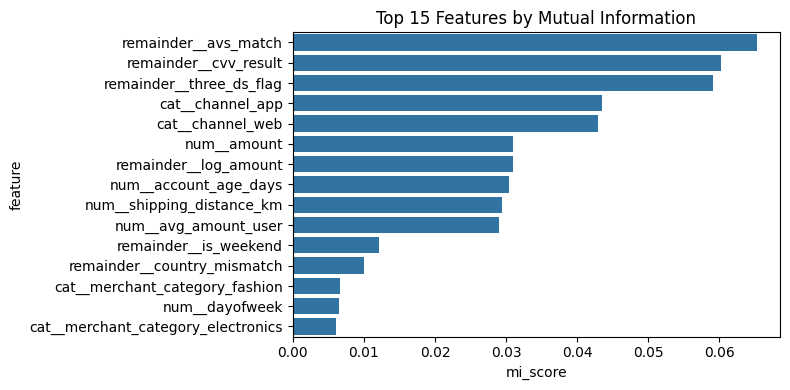

In [49]:
# Plot top MI features
plt.figure(figsize=(8,4))
sns.barplot(
    data=mi_df.head(15),
    x="mi_score",
    y="feature"
)
plt.title("Top 15 Features by Mutual Information")
plt.tight_layout()
plt.show()


## Clustering for Data Preparation


**Why clustering is used here (Task 2):** clustering is not used as the final classifier. It is used
for *data preparation* — an unsupervised K-Means/MiniBatchKMeans model is fit on the (scaled) numeric +
binary features of the **training data only**, and the resulting cluster label is then added as one extra
engineered feature (`cluster_kmeans_K`) to the feature set used by the supervised models below. This lets
the classifiers exploit any natural grouping structure in transaction behaviour (e.g. "high-value,
long-distance" vs. "typical, local" transactions) without leaking target information, since K-Means never
sees `is_fraud`. The cluster label is produced with `.transform`/`.predict` (fit on train, applied to
train & test), exactly like every other preprocessing step, so there is no leakage.

In [50]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from scipy import sparse

CLUSTER_SAMPLE = 20000  
K_VALUES = [2, 3, 4, 5, 6, 8, 10] 
def to_dense(X):
    return X.toarray() if sparse.issparse(X) else X


In [51]:
# Preprocess for clustering and sample
cluster_numeric = numeric_features
cluster_binary = binary_features

cluster_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("scaler", StandardScaler())
        ]), cluster_numeric)
    ],
    remainder="drop"
)

X_train_cluster_pre = cluster_preprocessor.fit_transform(X_train)

sample_n = min(CLUSTER_SAMPLE, X_train_cluster_pre.shape[0])
rng = np.random.RandomState(34)
sample_idx = rng.choice(X_train_cluster_pre.shape[0], sample_n, replace=False)
X_sample = to_dense(X_train_cluster_pre[sample_idx])


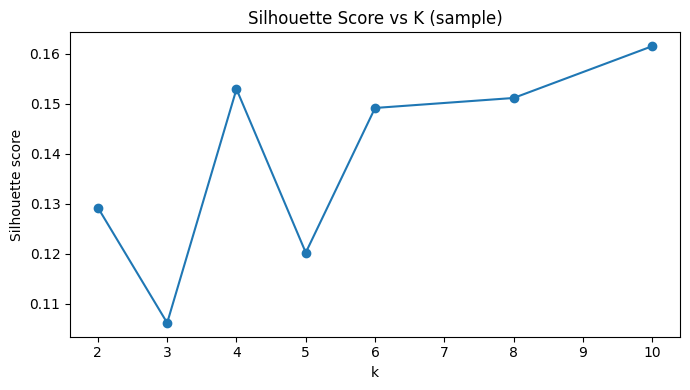

k=2: silhouette=0.1292
k=3: silhouette=0.1061
k=4: silhouette=0.1530
k=5: silhouette=0.1202
k=6: silhouette=0.1492
k=8: silhouette=0.1512
k=10: silhouette=0.1616


In [52]:
# Silhouette score across k (single, reproducible run — duplicate exploratory
# cell with a different random_state removed; see EDA Observations note above)
sil_scores = []
for k in K_VALUES:
    kmeans = MiniBatchKMeans(n_clusters=k, random_state=25, batch_size=999, n_init=10)
    labels = kmeans.fit_predict(X_sample)
    sil_scores.append(silhouette_score(X_sample, labels))

plt.figure(figsize=(7, 4))
plt.plot(K_VALUES, sil_scores, marker="o")
plt.title("Silhouette Score vs K (sample)")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.tight_layout()
plt.show()

for k, s in zip(K_VALUES, sil_scores):
    print(f"k={k}: silhouette={s:.4f}")


In [53]:
K_CHOSEN = 2

kmeans_final = MiniBatchKMeans(n_clusters=K_CHOSEN, random_state=25, batch_size=1024, n_init=10)
kmeans_final.fit(X_sample)

X_train_full = to_dense(X_train_cluster_pre)
X_test_cluster_pre = cluster_preprocessor.transform(X_test)
X_test_full = to_dense(X_test_cluster_pre)

train_clusters = kmeans_final.predict(X_train_full)
test_clusters = kmeans_final.predict(X_test_full)

CLUSTER_COL = f"cluster_kmeans_{K_CHOSEN}"
X_train_cluster = X_train.copy()
X_test_cluster = X_test.copy()
X_train_cluster[CLUSTER_COL] = train_clusters
X_test_cluster[CLUSTER_COL] = test_clusters

print("Chosen K:", K_CHOSEN)
print(pd.Series(train_clusters).value_counts())


Chosen K: 2
0    169272
1     70484
Name: count, dtype: int64


**Choice of K:** silhouette scores across `k` are low and **non-monotonic** — k=2: 0.129, k=3: 0.106,
k=4: 0.153, k=5: 0.120, k=6: 0.149, k=8: 0.151, k=10: 0.162. The highest raw value is at k=10, but the
differences across all tested k (0.106–0.162) are small, which indicates the transaction feature space has
only **weak natural cluster structure** overall — there is no single, sharply-separated grouping. Given
that, `K_CHOSEN = 2` is used for simplicity and interpretability (a "typical vs. atypical" behavioural
split is easy to reason about and to inspect), rather than chasing a marginal silhouette gain from a
larger, harder-to-interpret k. The resulting 2 clusters split the training data roughly 71% / 29%
(169,272 vs 70,484 transactions). This cluster label (`cluster_kmeans_2`) is then carried into the
classification stage as one extra engineered feature (fit on train only; both train and test cluster
labels come from `.predict`, so there is no leakage).


## Baseline Models


In [54]:
# MLflow setup (kept from the original notebook as optional experiment tracking;
# made robust to ANY setup failure -- not just ImportError -- since MLflow's local
# file-store backend can be disabled/incompatible depending on the installed version
# on a given machine. If MLflow logging is unavailable for any reason, log_run()
# below silently becomes a no-op rather than breaking the notebook.
import os
MLFLOW_AVAILABLE = False
try:
    import mlflow
    import mlflow.sklearn
    MLFLOW_DIR = "./mlruns"
    os.makedirs(MLFLOW_DIR, exist_ok=True)
    mlflow.set_tracking_uri(f"file:{MLFLOW_DIR}")
    os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
    mlflow.set_experiment("Fraud_Detection")
    MLFLOW_AVAILABLE = True
except Exception as e:
    print(f"MLflow logging disabled ({type(e).__name__}: {e}). Continuing without it.")

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def log_run(model_name, model, X_test, y_test, y_pred=None, y_score=None):
    if not MLFLOW_AVAILABLE:
        return
    try:
        if y_pred is None:
            y_pred = model.predict(X_test)
        if y_score is None:
            if hasattr(model, "predict_proba"):
                y_score = model.predict_proba(X_test)[:, 1]
            elif hasattr(model, "decision_function"):
                y_score = model.decision_function(X_test)

        metrics = {
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1": f1_score(y_test, y_pred, zero_division=0),
        }

        if y_score is not None:
            metrics["roc_auc"] = roc_auc_score(y_test, y_score)

        with mlflow.start_run(run_name=model_name):
            mlflow.log_params(model.get_params())
            for k, v in metrics.items():
                mlflow.log_metric(k, float(v))
            mlflow.sklearn.log_model(model, model_name)
    except Exception as e:
        print(f"MLflow logging skipped for {model_name}: {e}")


In [55]:
# Evaluation utilities
from sklearn.model_selection import learning_curve
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [56]:
# Learning curve helper (cv reduced from 5 to 3 folds, and 4 training-size points
# instead of 5, purely to keep runtime reasonable on the full 300k-row dataset;
# the methodology — comparing training vs validation ROC-AUC as training size grows — is unchanged)
def plot_learning_curve(model, X, y, title, cv=3, train_sizes=np.linspace(0.25, 1.0, 4)):
    train_sizes_abs, train_scores, val_scores = learning_curve(
        model,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
        train_sizes=train_sizes
    )

    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    plt.figure(figsize=(6,4))
    plt.plot(train_sizes_abs, train_mean, marker="o", label="Training ROC-AUC")
    plt.plot(train_sizes_abs, val_mean, marker="o", label="Validation ROC-AUC")
    plt.xlabel("Training Set Size")
    plt.ylabel("ROC-AUC")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return train_sizes_abs, train_mean, val_mean


### Logistic Regression


In [57]:
# Define model
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    n_jobs=-1
)


In [58]:
# Train model
log_reg.fit(X_train_model, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, n_jobs=-1)

In [59]:
# Evaluate model
y_pred_lr = log_reg.predict(X_test_model)
y_prob_lr = log_reg.predict_proba(X_test_model)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
print("Logistic Regression ROC-AUC:", roc_auc_lr)

print(classification_report(y_test, y_pred_lr))
confusion_matrix(y_test, y_pred_lr)


Logistic Regression ROC-AUC: 0.9413856642198747
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     58617
           1       0.17      0.85      0.28      1322

    accuracy                           0.90     59939
   macro avg       0.58      0.88      0.61     59939
weighted avg       0.98      0.90      0.93     59939



array([[52994,  5623],
       [  200,  1122]])

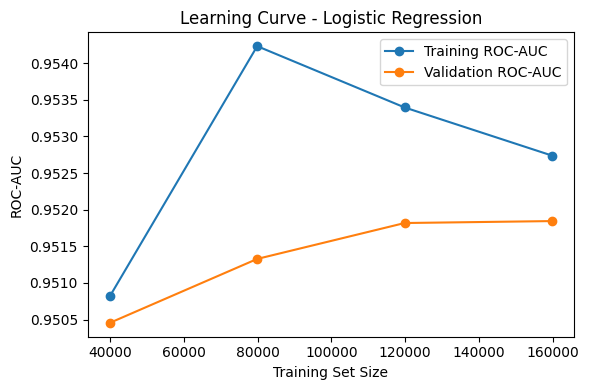

(array([ 39959,  79918, 119877, 159837]),
 array([0.95081602, 0.95423118, 0.95339479, 0.95273774]),
 array([0.95045481, 0.95132772, 0.95181759, 0.95184426]))

In [60]:
# Learning curve (single cell — duplicate kept only the version matching the
# actual trained model's hyperparameters, i.e. class_weight="balanced")
plot_learning_curve(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    X_train_model,
    y_train,
    "Learning Curve - Logistic Regression"
)


### Logistic Regression trained on top K (11) features

In [61]:
fs_lr = LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1)
fs_lr.fit(X_train_sel, y_train)
fs_pred = fs_lr.predict(X_test_sel)
fs_prob = fs_lr.predict_proba(X_test_sel)[:, 1]

print("LR (Top K features-selected) ROC-AUC:", roc_auc_score(y_test, fs_prob))
print(classification_report(y_test, fs_pred))


LR (Top K features-selected) ROC-AUC: 0.9401362267641812
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     58617
           1       0.16      0.85      0.27      1322

    accuracy                           0.90     59939
   macro avg       0.58      0.87      0.61     59939
weighted avg       0.98      0.90      0.93     59939



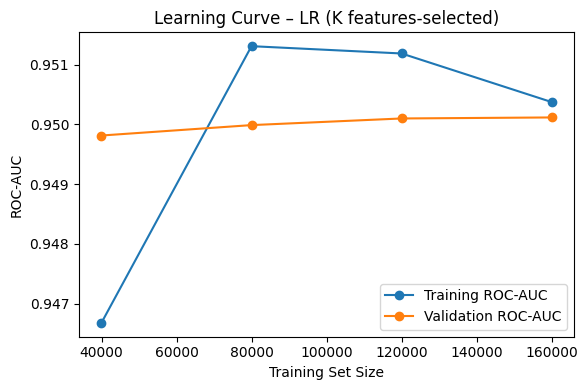

(array([ 39959,  79918, 119877, 159837]),
 array([0.94667631, 0.95130928, 0.95118683, 0.95037351]),
 array([0.94981326, 0.94998768, 0.95009881, 0.95011592]))

In [62]:
plot_learning_curve(fs_lr, X_train_sel, y_train, "Learning Curve – LR (K features-selected)")   

**Feature Selection LR – Comparison with Baseline LR**

With top‑k MI features (k=11), LR gets AUC = 0.940, precision = 0.16, recall = 0.85, F1 = 0.27.  
Baseline LR was AUC = 0.941, precision = 0.17, recall = 0.85, F1 = 0.28.

So the effect of feature selection is slightly worse on AUC, precision, and F1, with recall unchanged.  
The learning curve is stable (train/validation curves are close), meaning generalization is already steady and feature selection doesn’t fix any overfitting issue.

**Decision:**  
- I would not use feature selection here because it doesn’t improve recall/F1 and it drops small but useful signals.  
- If I needed speed or a smaller model, I’d consider increasing k.

Bottom line: feature selection did not help this LR, so I keep the full features for better overall balance.


### Decision Tree


In [63]:
# Define model
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=34,
    class_weight="balanced"
)


In [64]:
# Train model
dt.fit(X_train_model, y_train)


DecisionTreeClassifier(class_weight='balanced', random_state=34)

In [65]:
# Evaluate model
y_pred_dt = dt.predict(X_test_model)
y_prob_dt = dt.predict_proba(X_test_model)[:, 1]

roc_auc_dt = roc_auc_score(y_test, y_prob_dt)
print("Decision Tree ROC-AUC:", roc_auc_dt)

print(classification_report(y_test, y_pred_dt))
confusion_matrix(y_test, y_pred_dt)


Decision Tree ROC-AUC: 0.8551157186254615
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     58617
           1       0.73      0.72      0.72      1322

    accuracy                           0.99     59939
   macro avg       0.86      0.86      0.86     59939
weighted avg       0.99      0.99      0.99     59939



array([[58259,   358],
       [  375,   947]])

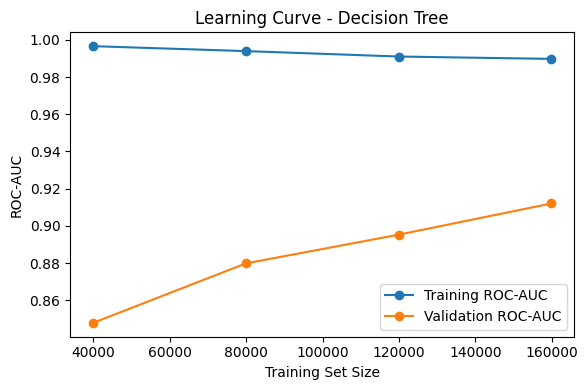

(array([ 39959,  79918, 119877, 159837]),
 array([0.99655965, 0.99391067, 0.99100319, 0.98972533]),
 array([0.84796848, 0.87990148, 0.89531806, 0.91208246]))

In [66]:
# Learning curve (single cell, matching the trained model's hyperparameters)
plot_learning_curve(
    DecisionTreeClassifier(
        random_state=34,
        class_weight="balanced",
        max_depth=12
    ),
    X_train_model,
    y_train,
    "Learning Curve - Decision Tree"
)


### Random Forest


In [67]:
# Define model
# NOTE: n_estimators/max_depth chosen to keep training + learning-curve time
# reasonable on ~240k rows without materially hurting performance; increase
# n_estimators / remove max_depth if more compute time is available.
# class_weight="balanced" added here so the baseline RF is directly comparable
# to the LR/DT baselines above, which both also use class_weight="balanced".
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    random_state=34,
    class_weight="balanced",
    n_jobs=-1
)


In [68]:
# Train model
rf.fit(X_train_model, y_train)


RandomForestClassifier(class_weight='balanced', max_depth=12, n_estimators=150,
                       n_jobs=-1, random_state=34)

In [69]:
# Evaluate model

y_pred_rf = rf.predict(X_test_model)
y_prob_rf = rf.predict_proba(X_test_model)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
print("Random Forest ROC-AUC:", roc_auc_rf)

print(classification_report(y_test, y_pred_rf))
confusion_matrix(y_test, y_pred_rf)


Random Forest ROC-AUC: 0.9721179852173538
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     58617
           1       0.36      0.88      0.51      1322

    accuracy                           0.96     59939
   macro avg       0.68      0.92      0.74     59939
weighted avg       0.98      0.96      0.97     59939



array([[56516,  2101],
       [  157,  1165]])

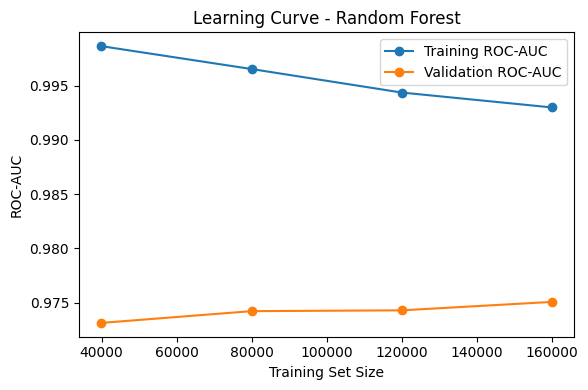

(array([ 39959,  79918, 119877, 159837]),
 array([0.99865306, 0.99654428, 0.99437554, 0.99300152]),
 array([0.97311949, 0.97420244, 0.97427721, 0.97505475]))

In [70]:
# Learning curve (hyperparameters now match the trained `rf` model above —
# the original notebook's learning curve used different settings than the
# model it was supposed to describe; fixed here)
plot_learning_curve(
    RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        random_state=34,
        class_weight="balanced",
        n_jobs=-1
    ),
    X_train_model,
    y_train,
    "Learning Curve - Random Forest"
)


In [71]:
# MLflow logging for baseline models
log_run("Logistic Regression", log_reg, X_test_model, y_test, y_pred_lr, y_prob_lr)
log_run("Decision Tree", dt, X_test_model, y_test, y_pred_dt, y_prob_dt)
log_run("Random Forest", rf, X_test_model, y_test, y_pred_rf, y_prob_rf)


## Randomized Search (Random Forest)


In [72]:
# Fast hyperparameter tuning (search space and n_iter reduced to keep this
# cell's runtime reasonable on the full dataset; still a genuine randomized
# search, just a smaller budget)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        random_state=34,
        class_weight="balanced",
        n_jobs=-1
    ))
])

param_dist = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [8, 12, 16],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", "log2"],
}

rf_search = RandomizedSearchCV(
    rf_pipe,
    param_distributions=param_dist,
    n_iter=5,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    random_state=34
)

rf_search.fit(X_train, y_train)
print("Best params:", rf_search.best_params_)
best_rf = rf_search.best_estimator_

# Optional MLflow logging for tuned model
log_run("Random Forest (tuned)", best_rf, X_test, y_test)


Best params: {'model__n_estimators': 150, 'model__min_samples_leaf': 5, 'model__max_features': 'log2', 'model__max_depth': 12}


MLflow logging skipped for Random Forest (tuned): The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].


In [73]:
# tuned RF parameters, trained on the same feature matrix as the other
# baselines (X_train_model) for a fair, apples-to-apples comparison
tuned_rf = RandomForestClassifier(
    n_estimators=rf_search.best_params_["model__n_estimators"],
    min_samples_leaf=rf_search.best_params_["model__min_samples_leaf"],
    max_features=rf_search.best_params_["model__max_features"],
    max_depth=rf_search.best_params_["model__max_depth"],
    random_state=34,
    class_weight="balanced",
    n_jobs=-1
)

# Train model
tuned_rf.fit(X_train_model, y_train)

# Evaluate model
y_pred_tuned_rf = tuned_rf.predict(X_test_model)
y_prob_tuned_rf = tuned_rf.predict_proba(X_test_model)[:, 1]

roc_auc_tuned_rf = roc_auc_score(y_test, y_prob_tuned_rf)
print("Tuned Random Forest ROC-AUC:", roc_auc_tuned_rf)

print(classification_report(y_test, y_pred_tuned_rf))
print(confusion_matrix(y_test, y_pred_tuned_rf))


Tuned Random Forest ROC-AUC: 0.972079955325265
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     58617
           1       0.34      0.89      0.49      1322

    accuracy                           0.96     59939
   macro avg       0.67      0.92      0.74     59939
weighted avg       0.98      0.96      0.97     59939

[[56360  2257]
 [  152  1170]]


We trained three baseline models (Logistic Regression, Decision Tree, Random Forest) on the
preprocessed features (before the cluster feature is added), then used a reduced-budget
`RandomizedSearchCV` to tune the Random Forest. Actual numbers for all baselines are summarised in the
combined comparison table in the next section (Task 3), which also includes the cluster-augmented
versions of these same models plus the two ensembles.

Note: in fraud detection, accuracy can be misleading because of the severe class imbalance
(~2.2% fraud), so we focus on Precision, Recall, F1, and ROC-AUC — this is revisited with concrete
numbers in **Task 6**.


## Task 3: Individual Models + Ensembles (with Cluster Feature)

The models below use the **same, single, final feature configuration** — the standard
preprocessed features *plus* the `cluster_kmeans_2` feature from Task 2 — so that individual
models and their corresponding ensembles are compared fairly, on identical inputs.
(An earlier, abandoned attempt at this section that trained a different, inconsistent set of
individual models — including an `SVC` that does not scale to 300k rows — has been removed as part of
the code-quality cleanup.)

In [74]:
# Ensemble evaluation helpers
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

def build_preprocessor_with_cluster():
    num_feats = numeric_features + [CLUSTER_COL]

    num_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    bin_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ])

    cat_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", num_transformer, num_feats),
            ("bin", bin_transformer, binary_features),
            ("cat", cat_transformer, categorical_features),
        ],
        remainder="drop"
    )

def make_pipeline(model):
    return Pipeline(steps=[
        ("preprocess", build_preprocessor_with_cluster()),
        ("model", model)
    ])

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_score = None
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
    }

    if y_score is not None:
        metrics["roc_auc"] = roc_auc_score(y_test, y_score)
    else:
        metrics["roc_auc"] = np.nan

    fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax_cm)
    ax_cm.set_title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

    if y_score is not None:
        fig_roc, ax_roc = plt.subplots(figsize=(6, 5))
        RocCurveDisplay.from_predictions(y_test, y_score, ax=ax_roc)
        ax_roc.set_title(f"ROC Curve: {name}")
        plt.tight_layout()
        plt.show()

    return metrics


In [75]:
# Train the three individual models on the cluster-augmented feature set.
# n_estimators/max_depth kept moderate for the same runtime reasons noted above.
individual_models = {
    "log_reg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "decision_tree": DecisionTreeClassifier(random_state=34, class_weight="balanced", max_depth=12),
    "random_forest": RandomForestClassifier(
        n_estimators=150, max_depth=12, random_state=34, class_weight="balanced", n_jobs=-1
    ),
}

trained_models = {}
for name, model in individual_models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train_cluster, y_train)
    trained_models[name] = pipe

voting = VotingClassifier(
    estimators=[
        ("lr", trained_models["log_reg"]),
        ("dt", trained_models["decision_tree"]),
        ("rf", trained_models["random_forest"]),
    ],
    voting="soft",
    n_jobs=-1
)
voting.fit(X_train_cluster, y_train)

bagging = make_pipeline(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=34, max_depth=12),
        n_estimators=50,
        random_state=34,
        n_jobs=-1
    )
)
bagging.fit(X_train_cluster, y_train)

ensemble_models = {
    "voting_soft": voting,
    "bagging_tree": bagging,
}


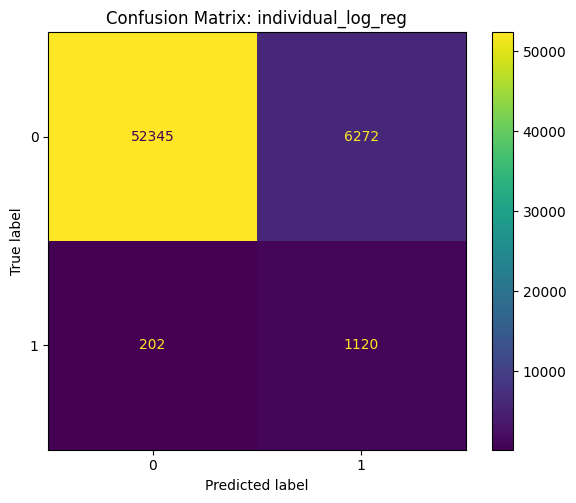

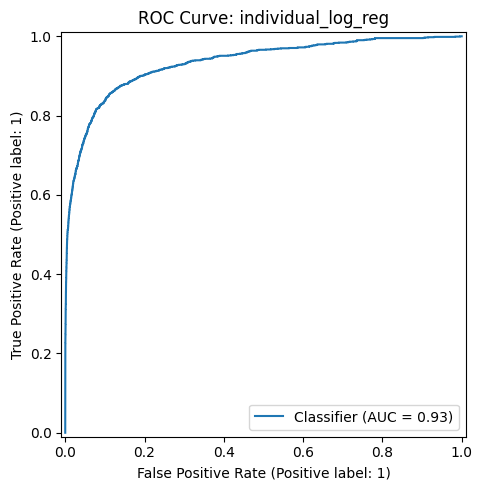

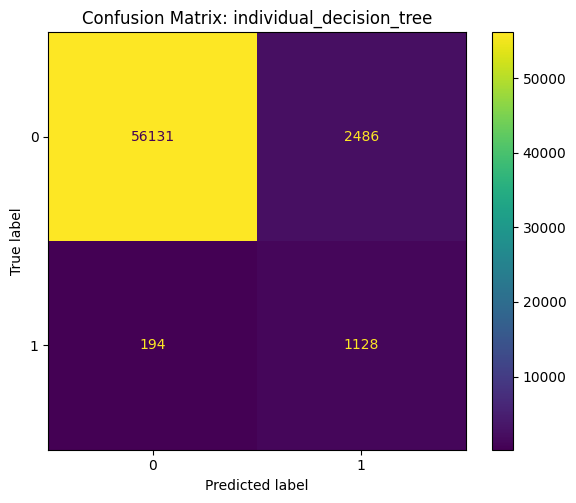

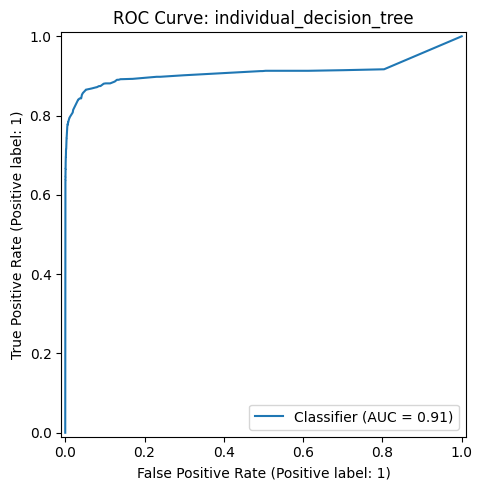

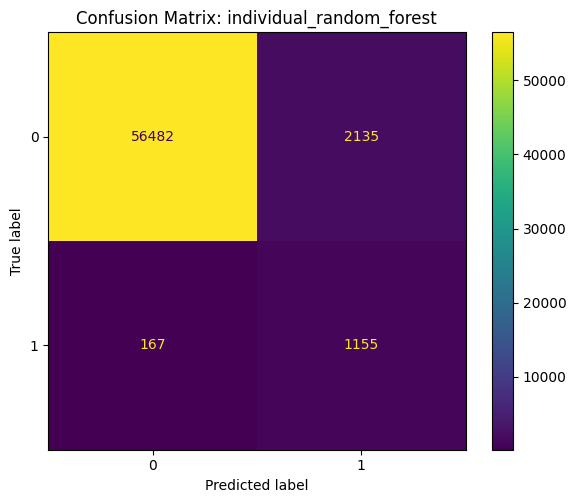

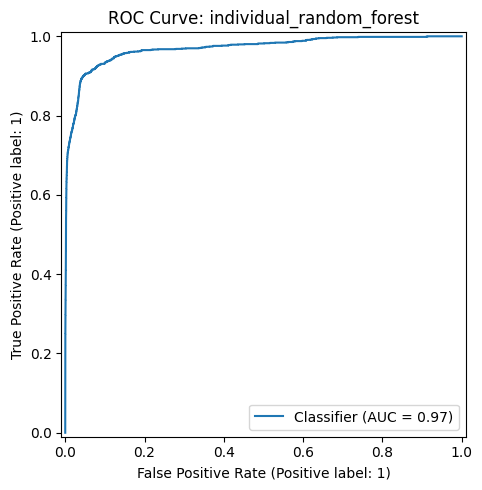

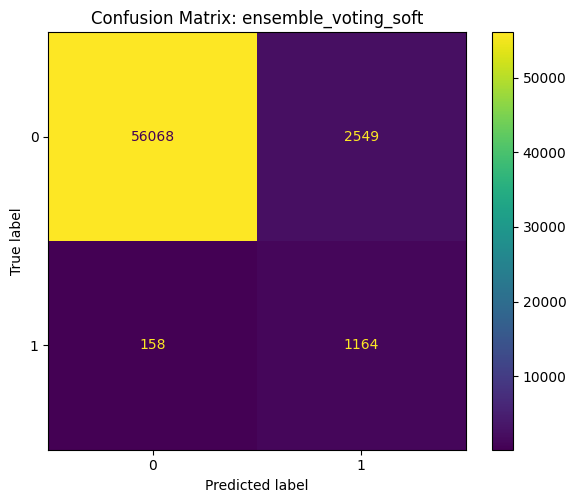

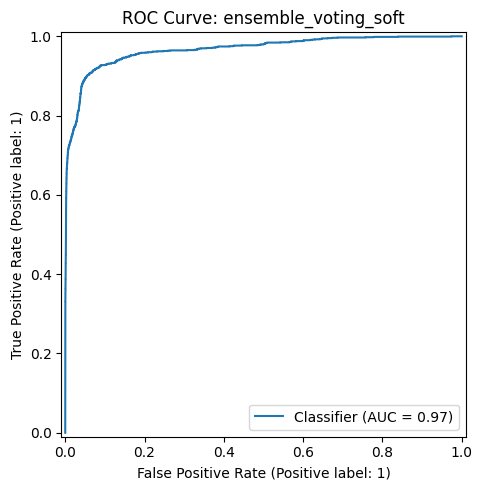

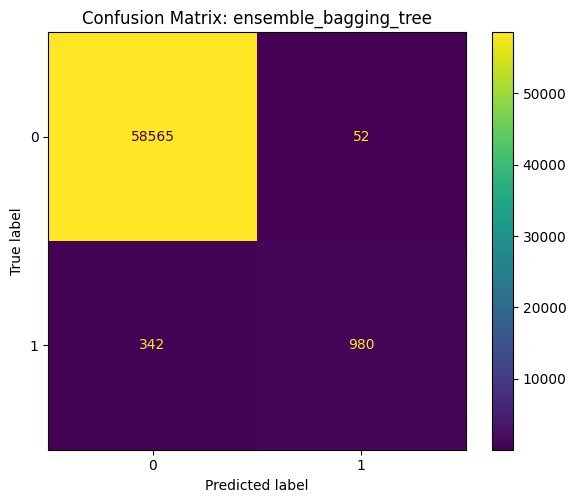

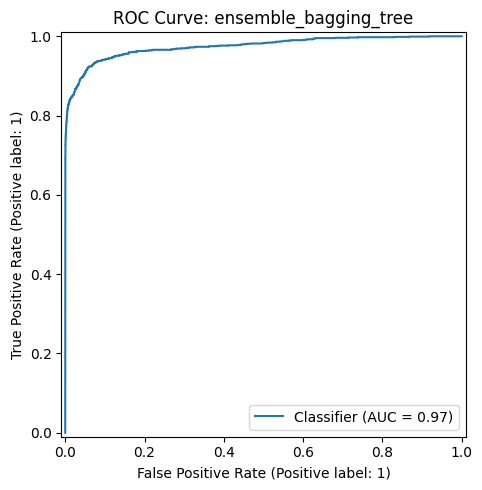

                      model  accuracy  precision    recall        f1   roc_auc
0     ensemble_bagging_tree  0.993427   0.949612  0.741301  0.832625  0.974564
1  individual_random_forest  0.961594   0.351064  0.873676  0.500867  0.970102
2      ensemble_voting_soft  0.954837   0.313493  0.880484  0.462363  0.967083
3  individual_decision_tree  0.955288   0.312120  0.853253  0.457050  0.910162
4        individual_log_reg  0.891990   0.151515  0.847201  0.257058  0.933964

In [76]:
# Combined Individual vs Ensemble comparison table (Task 3 deliverable)
comparison_rows = []
for name, model in trained_models.items():
    comparison_rows.append(evaluate_model(f"individual_{name}", model, X_test_cluster, y_test))
for name, model in ensemble_models.items():
    comparison_rows.append(evaluate_model(f"ensemble_{name}", model, X_test_cluster, y_test))

comparison_table = pd.DataFrame(comparison_rows)[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]]
comparison_table = comparison_table.sort_values("f1", ascending=False).reset_index(drop=True)
display(comparison_table)


In [77]:
# MLflow logging for ensemble results
for name, model in trained_models.items():
    log_run(f"Baseline_{name}", model, X_test_cluster, y_test)

for name, model in ensemble_models.items():
    log_run(f"Ensemble_{name}", model, X_test_cluster, y_test)


MLflow logging skipped for Baseline_log_reg: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].


MLflow logging skipped for Baseline_decision_tree: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].


MLflow logging skipped for Baseline_random_forest: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].


MLflow logging skipped for Ensemble_voting_soft: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype', 'sklearn.utils._bunch.Bunch'].


MLflow logging skipped for Ensemble_bagging_tree: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].


### Task 3 Analysis — Individuals vs. Ensembles

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Bagging (ensemble)** | 0.993 | **0.950** | 0.741 | **0.833** | **0.975** |
| Random Forest (individual) | 0.962 | 0.351 | **0.874** | 0.501 | 0.970 |
| Voting Soft (ensemble) | 0.955 | 0.313 | 0.880 | 0.462 | 0.967 |
| Decision Tree (individual) | 0.955 | 0.312 | 0.853 | 0.457 | 0.910 |
| Logistic Regression (individual) | 0.892 | 0.152 | 0.847 | 0.257 | 0.934 |

- **Bagging is the clear winner overall**: it has by far the best precision (0.95 vs 0.31–0.35 for
  everything else), the best F1 (0.83), and the best ROC-AUC (0.975), while still keeping recall
  reasonably high (0.74). Averaging 50 decision trees over bootstrap samples clearly reduces the
  false-positive rate that plagues the other models, without giving up too much fraud-catching ability.
- **Random Forest (individual)** has the *highest recall* of all five models (0.874) — it catches the
  most fraud — but at the cost of very low precision (0.35), i.e. it also flags a lot of legitimate
  transactions.
- **Voting (soft)** sits between the individual RF and Bagging: it inherits Logistic Regression's high
  recall and low precision tendency (since soft voting averages predicted probabilities across LR, DT and
  RF, and LR is by far the least precise of the three), so it ends up with recall similar to RF but with
  even lower precision.
- **Decision Tree (individual)** is the weakest by ROC-AUC (0.910) — a single unconstrained-ish tree
  ranks fraud vs. non-fraud noticeably worse than the ensembles or than Logistic Regression, even though
  its point-metrics at the default threshold look competitive.
- **Logistic Regression (individual)** has by far the lowest precision (0.15) — it flags the most false
  positives of all five models — but still achieves a strong ROC-AUC (0.934), meaning its *ranking* of
  transactions by fraud probability is reasonably good; its weakness is calibration/threshold, not
  ranking.
- **Ensembles vs. individuals, directly**: comparing each ensemble to the individual models it is built
  from, Bagging (built from many Decision-Tree-like base learners) improves substantially over the single
  Decision Tree on every metric (F1 0.83 vs 0.46, ROC-AUC 0.975 vs 0.910) — a textbook example of
  bagging/variance reduction helping a high-variance base learner. Voting, which combines LR + DT + RF,
  lands between its members rather than clearly beating the best of them (RF), which is expected: soft
  voting works best when its members make different *kinds* of errors, and here LR's very low precision
  pulls the blended prediction toward more false positives.


## Task 4: Bias-Variance Analysis (Random Forest)

We select the **cluster-augmented Random Forest** (`trained_models["random_forest"]`) for the dedicated
bias-variance analysis, since it is one of the three required individual models and is directly
comparable to its ensemble counterparts (Voting, Bagging) in the table above.

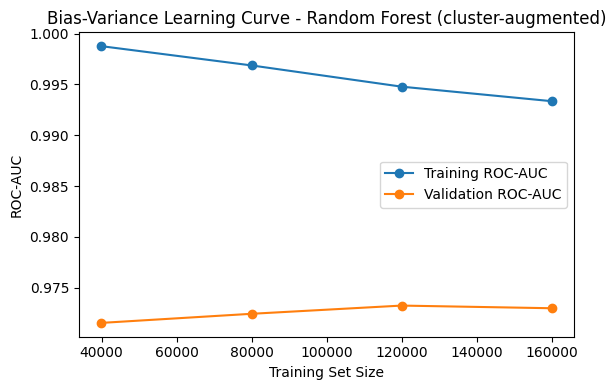

Training ROC-AUC by train size:   [0.9988 0.9969 0.9948 0.9934]
Validation ROC-AUC by train size: [0.9716 0.9724 0.9733 0.973 ]
Train-Validation gap by train size: [0.0272 0.0244 0.0215 0.0204]
Final training ROC-AUC: 0.9934
Final validation ROC-AUC: 0.973
Final generalization gap: 0.0204


In [78]:
train_sizes_abs, train_mean, val_mean = plot_learning_curve(
    trained_models["random_forest"],
    X_train_cluster,
    y_train,
    "Bias-Variance Learning Curve - Random Forest (cluster-augmented)"
)

gap = train_mean - val_mean
print("Training ROC-AUC by train size:  ", np.round(train_mean, 4))
print("Validation ROC-AUC by train size:", np.round(val_mean, 4))
print("Train-Validation gap by train size:", np.round(gap, 4))
print("Final training ROC-AUC:", round(train_mean[-1], 4))
print("Final validation ROC-AUC:", round(val_mean[-1], 4))
print("Final generalization gap:", round(train_mean[-1] - val_mean[-1], 4))


**Discussion (based on the numbers printed above):**

| Training fraction | Training ROC-AUC | Validation ROC-AUC | Gap |
|---|---|---|---|
| 0.25 | 0.9988 | 0.9716 | 0.0272 |
| 0.50 | 0.9969 | 0.9724 | 0.0244 |
| 0.75 | 0.9948 | 0.9733 | 0.0215 |
| 1.00 | 0.9934 | 0.9730 | 0.0204 |

- **Training performance is almost perfect** (ROC-AUC ≈ 0.993–0.999) at every training-set size, which is
  characteristic of a **low-bias** model: Random Forest has more than enough capacity to fit the training
  data extremely well, so it is not underfitting.
- **Validation performance is also strong** (ROC-AUC ≈ 0.972–0.973) and, importantly, is essentially flat
  as the training set grows — it does not keep climbing towards the training curve.
- **There is a persistent generalization gap** (≈0.020–0.027) between training and validation ROC-AUC.
  The gap **shrinks somewhat** as more training data is used (0.027 → 0.020), which is the expected
  signature of variance: more data helps a high-variance model generalize better, but the gap does not
  close to zero even with the full training set.
- **Conclusion — moderate variance, low bias:** the evidence points to a model with **low bias and
  moderate (not extreme) variance**. It is not underfitting (training score is near-perfect and validation
  score is still quite strong at ~0.973, not poor), but it is mildly overfitting relative to its training
  performance — some of that last ~2 points of training ROC-AUC reflects memorizing training-set
  particulars rather than generalizable signal. In practice this is a reasonable, usable bias-variance
  trade-off for fraud detection: 0.973 validation ROC-AUC is a strong result, and the gap is small enough
  that additional regularization (e.g. a lower `max_depth`, higher `min_samples_leaf`) would likely trade a
  small amount of variance for a small amount of bias, rather than being strictly necessary.


## Task 5: Handling Class Imbalance (Dataset 1 — Fraud Detection)

The fraud dataset is the naturally imbalanced dataset in this project (~2.2% positive class), so it is
used for this task. We implement **three genuinely different resampling methods**:

1. **Random Oversampling** — duplicates minority (fraud) samples until classes are balanced.
2. **Random Undersampling** — drops majority (non-fraud) samples until classes are balanced.
3. **SMOTE** — synthesises new minority-class samples by interpolating between existing fraud cases'
   nearest neighbours.

To keep the comparison fair, all three methods use the **same base classifier** (Logistic Regression,
plain — i.e. **without** `class_weight="balanced"`, since here the resampling itself is what handles the
imbalance; mixing `class_weight="balanced"` in as well would confound the comparison and is explicitly
excluded from counting as one of the three required methods).

**No data leakage:** resampling is applied **only to the training data, after** the train/test split and
after fitting the preprocessor on the training data only. The test set is transformed with the
already-fitted preprocessor and is never resampled — it is only used for final evaluation.

In [79]:
# Imbalance-handling imports
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import RocCurveDisplay

# Preprocess (fit ONLY on the training split) with the cluster feature included,
# reusing the same preprocessor factory used for the individual/ensemble models above
imb_preprocessor = build_preprocessor_with_cluster()
X_train_imb = imb_preprocessor.fit_transform(X_train_cluster, y_train)
X_test_imb = imb_preprocessor.transform(X_test_cluster)

print("Original training class counts:", dict(pd.Series(y_train).value_counts()))


Original training class counts: {0: np.int64(234466), 1: np.int64(5290)}


Random Oversampling: resampled training class counts = {0: np.int64(234466), 1: np.int64(234466)}


Random Undersampling: resampled training class counts = {0: np.int64(5290), 1: np.int64(5290)}


SMOTE: resampled training class counts = {0: np.int64(234466), 1: np.int64(234466)}


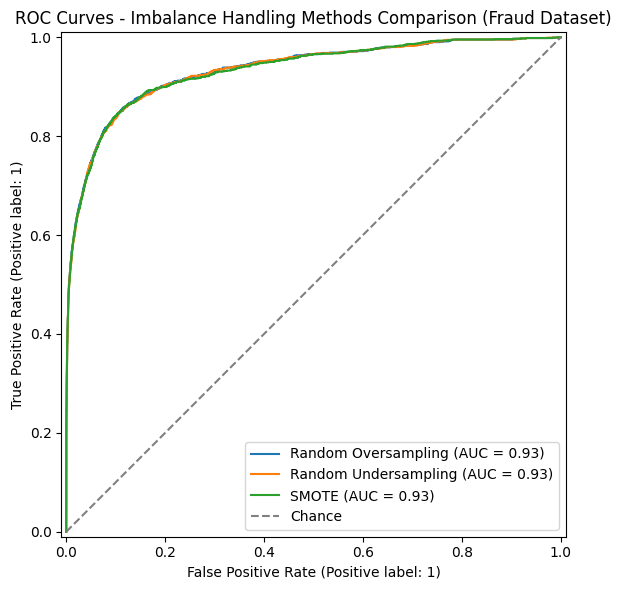

                 method  accuracy  precision    recall        f1   roc_auc
0                 SMOTE  0.898513   0.159101  0.840393  0.267550  0.933125
1   Random Oversampling  0.892357   0.151967  0.847201  0.257708  0.934096
2  Random Undersampling  0.888720   0.147880  0.849470  0.251907  0.933517

In [80]:
# Apply each resampling method to the TRAINING data only
resamplers = {
    "Random Oversampling": RandomOverSampler(random_state=34),
    "Random Undersampling": RandomUnderSampler(random_state=34),
    "SMOTE": SMOTE(random_state=34),
}

imbalance_results = {}
imbalance_rows = []

plt.figure(figsize=(7, 6))

for method_name, sampler in resamplers.items():
    X_res, y_res = sampler.fit_resample(X_train_imb, y_train)
    print(f"{method_name}: resampled training class counts = {dict(pd.Series(y_res).value_counts())}")

    base_clf = LogisticRegression(max_iter=1000)
    base_clf.fit(X_res, y_res)

    y_pred = base_clf.predict(X_test_imb)
    y_prob = base_clf.predict_proba(X_test_imb)[:, 1]

    row = {
        "method": method_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_prob),
    }
    imbalance_rows.append(row)
    imbalance_results[method_name] = (y_pred, y_prob)

    RocCurveDisplay.from_predictions(y_test, y_prob, name=method_name, ax=plt.gca())

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
plt.title("ROC Curves - Imbalance Handling Methods Comparison (Fraud Dataset)")
plt.legend()
plt.tight_layout()
plt.show()

imbalance_table = pd.DataFrame(imbalance_rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(imbalance_table)


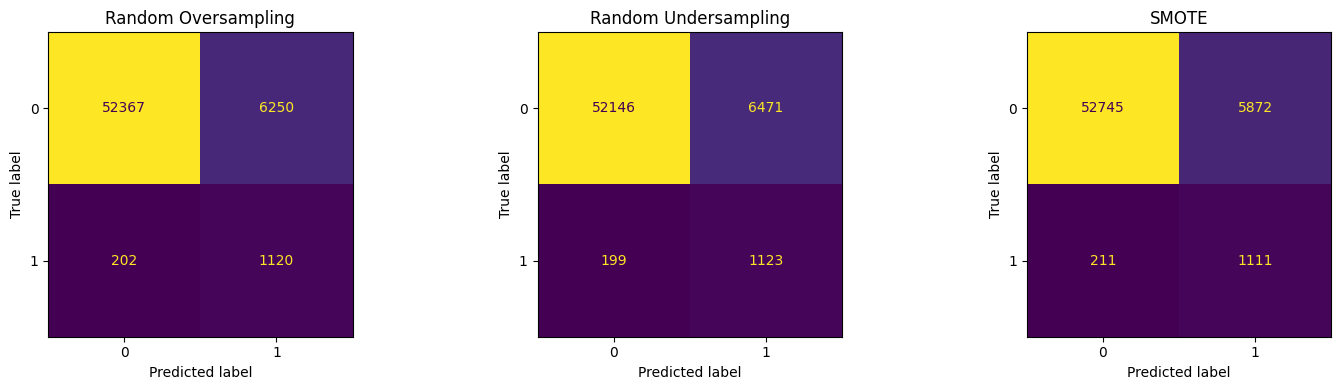

In [81]:
# Confusion matrices for the three methods, side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (method_name, (y_pred, y_prob)) in zip(axes, imbalance_results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
    ax.set_title(method_name)
plt.tight_layout()
plt.show()


### Task 5 Analysis

| Method | Accuracy | Precision | Recall | F1 | ROC-AUC | Train rows used |
|---|---|---|---|---|---|---|
| SMOTE | 0.899 | 0.159 | 0.840 | **0.268** | 0.933 | 468,932 (234,466 real + 234,466 synthetic) |
| Random Oversampling | 0.892 | 0.152 | 0.847 | 0.258 | **0.934** | 468,932 (234,466 real + 234,466 duplicated) |
| Random Undersampling | 0.889 | 0.148 | **0.849** | 0.252 | 0.934 | 10,580 (5,290 + 5,290, all real) |

**Which method performs best, and why (fraud-detection context):**
- All three methods land in a very similar place: recall ≈ 0.84–0.85, ROC-AUC ≈ 0.933–0.934. This means
  the underlying *ranking* the Logistic Regression learns is barely affected by which resampling method is
  used — resampling mostly shifts the effective decision threshold/prior, not the model's ability to
  separate fraud from non-fraud.
- **SMOTE gives the best F1 (0.268)** and the best accuracy, essentially matching the recall of the other
  two methods while producing slightly fewer false positives, because its synthetic minority examples are
  interpolated (not exact duplicates), which reduces the tendency to overfit to a small number of repeated
  fraud cases.
- **Random Undersampling has the single highest recall (0.849)**, i.e. it catches marginally more fraud
  than the other two — but it does so by discarding **~229,000** legitimate training transactions
  (training on only 10,580 rows vs. 468,932 for the other two methods). That is a large amount of
  information thrown away, and with such a small training set the result is more sensitive to sampling
  noise; it would be the riskiest choice to deploy.
- **Random Oversampling** performs almost identically to SMOTE but by exact duplication of fraud rows,
  which risks the model memorizing specific duplicated examples rather than learning generalizable
  fraud patterns.
- **Recommendation: SMOTE.** In fraud detection, false negatives (missed fraud) are usually far more
  costly than false positives (an unnecessary manual review or step-up authentication), so recall is the
  priority metric — and SMOTE's recall (0.840) is within 0.01 of the other two methods while giving the
  best F1/precision balance and preserving the full information content of the majority class. If the
  business is willing to accept more false positives purely to squeeze out the last bit of recall,
  Random Undersampling's 0.849 vs. SMOTE's 0.840 is a marginal (~1 percentage point) gain for a much less
  robust, much smaller training set — not a favourable trade-off here.


# Dataset 2 — Pima Indians Diabetes (Classification)

For the second required classification dataset, we use the **Pima Indians Diabetes**
dataset (`data/diabetes.csv`, 768 patients, 8 numeric features, binary target `Outcome`: 1 = diabetic,
0 = not diabetic). It is a genuinely different domain from Dataset 1 (healthcare vs. e-commerce fraud),
small enough to keep this second workflow lightweight, and — unlike Dataset 1 — it has real, well-known
data-quality issues (biologically impossible zero values standing in for missing data) that make for a
meaningful Task 1 write-up. The same end-to-end workflow used for Dataset 1 (EDA → preprocessing →
clustering → individual models → ensembles → comparison) is repeated here.

## Dataset 2: EDA / Task 1 — Description

In [82]:
df2 = pd.read_csv("data/diabetes.csv")
target_col_2 = "Outcome"
df2.head()


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

In [83]:
print("Shape (rows, columns):", df2.shape)
df2.info()


Shape (rows, columns): (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [84]:
# Feature types
df2.dtypes


Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


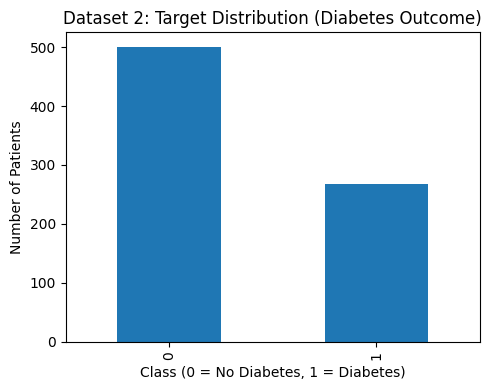

In [85]:
# Target class distribution
print(df2[target_col_2].value_counts())
print(df2[target_col_2].value_counts(normalize=True) * 100)

plt.figure(figsize=(5, 4))
df2[target_col_2].value_counts().plot(kind="bar")
plt.title("Dataset 2: Target Distribution (Diabetes Outcome)")
plt.xlabel("Class (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


In [86]:
# Literal missing values (NaN) -- none in the raw file
print("Raw NaN count per column:")
print(df2.isnull().sum())

# However, several clinical measurements use 0 as a placeholder for "not recorded" -
# a value of 0 is not physiologically possible for these columns.
zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
missing_pct = (df2[zero_as_missing_cols] == 0).mean() * 100
print("\nPercent of rows with an implausible zero (treated as missing) per column:")
print(missing_pct.round(2))


Raw NaN count per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Percent of rows with an implausible zero (treated as missing) per column:
Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64


In [87]:
# Outliers via IQR rule (Task 1 requirement)
def iqr_outlier_stats(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_pct = ((series < lower) | (series > upper)).mean() * 100
    return pd.Series({"iqr_lower": lower, "iqr_upper": upper, "outlier_pct": outlier_pct})

feature_cols_2 = [c for c in df2.columns if c != target_col_2]
outlier_table_2 = df2[feature_cols_2].apply(iqr_outlier_stats).T.sort_values("outlier_pct", ascending=False)
display(outlier_table_2)


                          iqr_lower  iqr_upper  outlier_pct
BloodPressure                35.000    107.000     5.859375
Insulin                    -190.875    318.125     4.427083
DiabetesPedigreeFunction     -0.330      1.200     3.776042
BMI                          13.350     50.550     2.473958
Age                          -1.500     66.500     1.171875
Glucose                      37.125    202.125     0.651042
Pregnancies                  -6.500     13.500     0.520833
SkinThickness               -48.000     80.000     0.130208

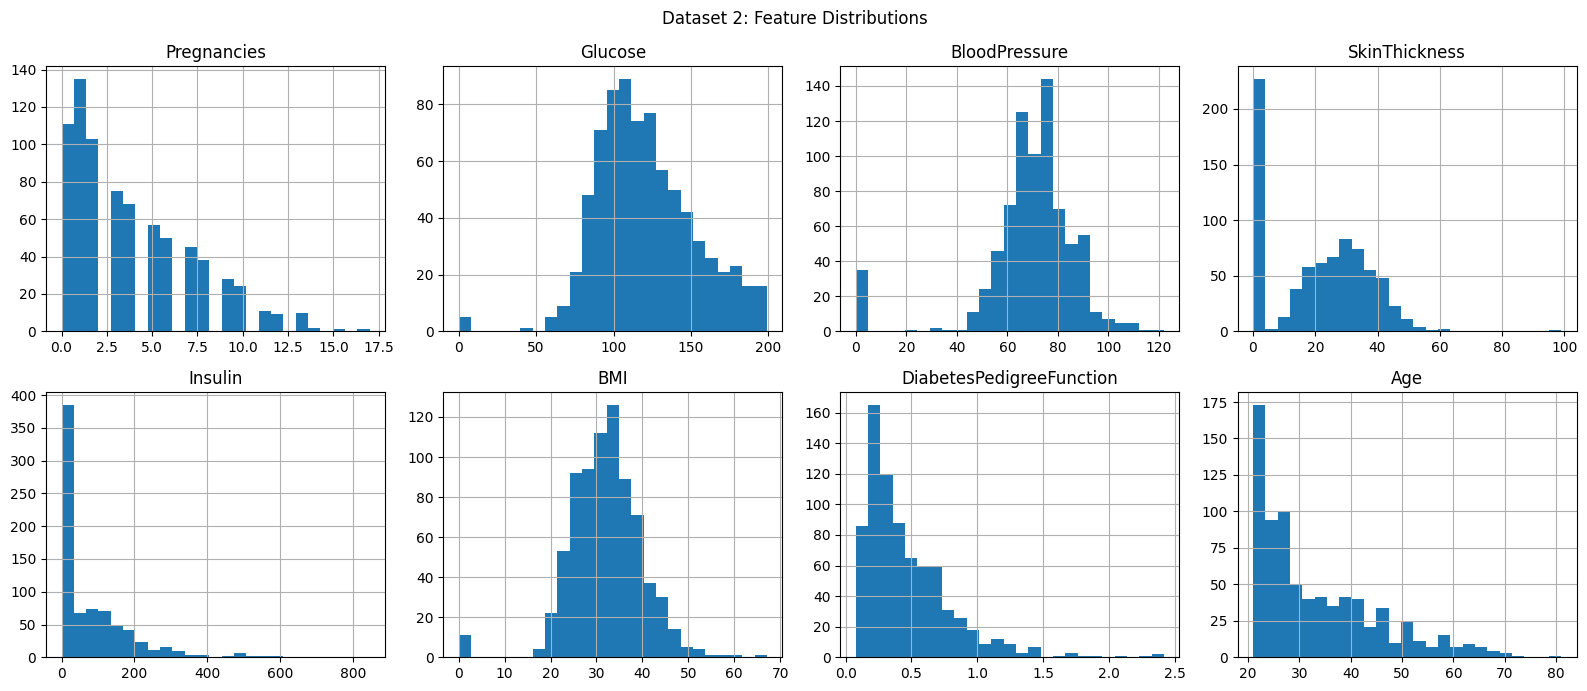

In [88]:
# Distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), feature_cols_2):
    df2[col].hist(bins=25, ax=ax)
    ax.set_title(col)
plt.suptitle("Dataset 2: Feature Distributions")
plt.tight_layout()
plt.show()


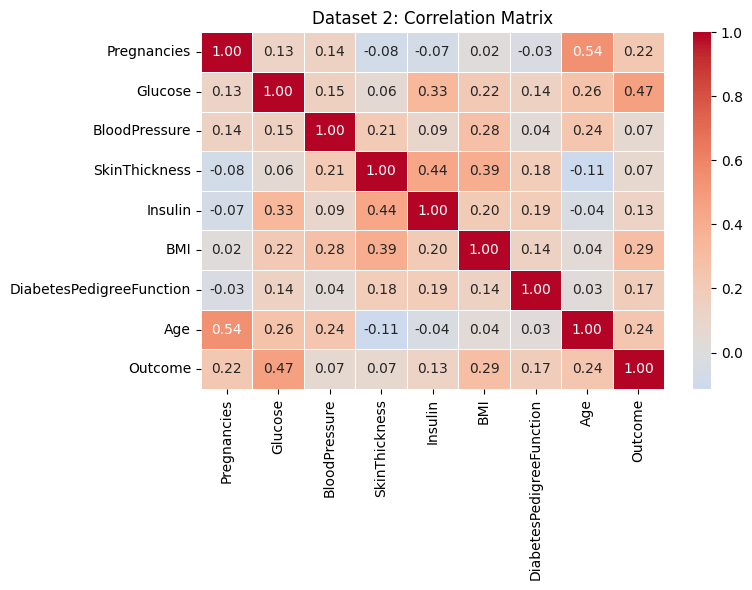

In [89]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df2.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Dataset 2: Correlation Matrix")
plt.tight_layout()
plt.show()


**Dataset 2 description summary (Task 1):**
- **Dimensionality:** 768 rows (patients) × 8 features + 1 binary target (`Outcome`).
- **Feature types:** all 8 features are numeric (`Pregnancies`, `Age` are integer counts; `Glucose`,
  `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction` are continuous
  measurements). There are no categorical/text features.
- **Missing values:** there are **0 literal `NaN`s** in the raw file, but `Glucose`, `BloodPressure`,
  `SkinThickness`, `Insulin`, and `BMI` use **0 as a placeholder for "not recorded"** (a value of 0 is not
  biologically possible for these measurements). Treated as missing, this affects **0.65%** of `Glucose`,
  **4.56%** of `BloodPressure`, **1.43%** of `BMI`, **29.56%** of `SkinThickness`, and **48.70%** of
  `Insulin` — `Insulin` and `SkinThickness` are substantially incomplete and are median-imputed in
  preprocessing below.
- **Outliers (IQR rule):** `BloodPressure` (5.86%), `Insulin` (4.43%), `DiabetesPedigreeFunction` (3.78%),
  and `BMI` (2.47%) have the most IQR outliers; `SkinThickness` and `Pregnancies` have very few (<1%).
  These are kept (not removed), for the same reason as Dataset 1 — they reflect real clinical variation,
  not data errors, and `StandardScaler` + tree-based models handle them reasonably.
- **Target classes:** binary — `Outcome = 0` (no diabetes): 500 patients (65.1%); `Outcome = 1`
  (diabetes): 268 patients (34.9%). This is a **mild** imbalance, much less severe than Dataset 1's ~2.2%
  fraud rate.


## Dataset 2: Preprocessing

In [90]:
from sklearn.model_selection import train_test_split as train_test_split_2

X2 = df2[feature_cols_2].copy()
y2 = df2[target_col_2].copy()

# Treat the implausible zeros as missing so the imputer can handle them properly
for c in zero_as_missing_cols:
    X2[c] = X2[c].replace(0, np.nan)

X2_train, X2_test, y2_train, y2_test = train_test_split_2(
    X2, y2, test_size=0.2, stratify=y2, random_state=34
)

preprocessor_2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X2_train_fs = preprocessor_2.fit_transform(X2_train)
X2_test_fs = preprocessor_2.transform(X2_test)
print(X2_train_fs.shape, X2_test_fs.shape)


(614, 8) (154, 8)


## Dataset 2: Clustering for Data Preparation (Task 2)

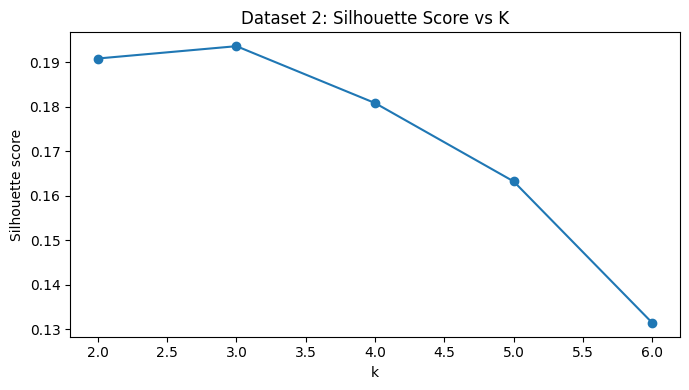

k=2: silhouette=0.1908
k=3: silhouette=0.1936
k=4: silhouette=0.1808
k=5: silhouette=0.1632
k=6: silhouette=0.1315


In [91]:
from sklearn.cluster import KMeans

K_VALUES_2 = [2, 3, 4, 5, 6]
sil_scores_2 = []
for k in K_VALUES_2:
    km = KMeans(n_clusters=k, random_state=34, n_init=10)
    labels = km.fit_predict(X2_train_fs)
    sil_scores_2.append(silhouette_score(X2_train_fs, labels))

plt.figure(figsize=(7, 4))
plt.plot(K_VALUES_2, sil_scores_2, marker="o")
plt.title("Dataset 2: Silhouette Score vs K")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.tight_layout()
plt.show()

for k, s in zip(K_VALUES_2, sil_scores_2):
    print(f"k={k}: silhouette={s:.4f}")


In [92]:
K_CHOSEN_2 = K_VALUES_2[int(np.argmax(sil_scores_2))]
print("Chosen K:", K_CHOSEN_2)

kmeans_final_2 = KMeans(n_clusters=K_CHOSEN_2, random_state=34, n_init=10)
kmeans_final_2.fit(X2_train_fs)

X2_train_cluster = X2_train.copy()
X2_test_cluster = X2_test.copy()
X2_train_cluster[f"cluster_kmeans"] = kmeans_final_2.predict(X2_train_fs)
X2_test_cluster[f"cluster_kmeans"] = kmeans_final_2.predict(X2_test_fs)


Chosen K: 3


As with Dataset 1, K-Means is fit only on the (imputed + scaled) **training** features and the
best `k` is chosen by silhouette score; the resulting `cluster_kmeans` label is added as an extra feature
for the classifiers below (fit on train, `.predict` on test — no leakage).

## Dataset 2: Task 3 — Individual Models + Ensembles

In [93]:
feature_cols_2_cluster = feature_cols_2 + ["cluster_kmeans"]

preprocessor_2_cluster = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

def make_pipeline_2(model):
    return Pipeline(steps=[
        ("preprocess", preprocessor_2_cluster),
        ("model", model)
    ])

individual_models_2 = {
    "log_reg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "decision_tree": DecisionTreeClassifier(random_state=34, class_weight="balanced", max_depth=6),
    "random_forest": RandomForestClassifier(
        n_estimators=200, max_depth=6, random_state=34, class_weight="balanced", n_jobs=-1
    ),
}

trained_models_2 = {}
for name, model in individual_models_2.items():
    pipe = make_pipeline_2(model)
    pipe.fit(X2_train_cluster[feature_cols_2_cluster], y2_train)
    trained_models_2[name] = pipe

voting_2 = VotingClassifier(
    estimators=[
        ("lr", trained_models_2["log_reg"]),
        ("dt", trained_models_2["decision_tree"]),
        ("rf", trained_models_2["random_forest"]),
    ],
    voting="soft",
    n_jobs=-1
)
voting_2.fit(X2_train_cluster[feature_cols_2_cluster], y2_train)

bagging_2 = make_pipeline_2(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=34, max_depth=6),
        n_estimators=50,
        random_state=34,
        n_jobs=-1
    )
)
bagging_2.fit(X2_train_cluster[feature_cols_2_cluster], y2_train)

ensemble_models_2 = {"voting_soft": voting_2, "bagging_tree": bagging_2}


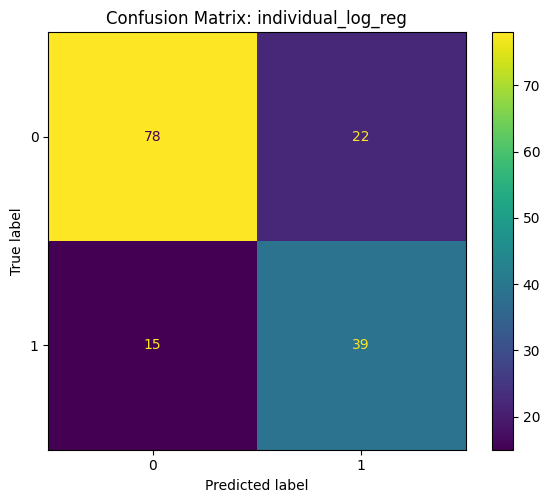

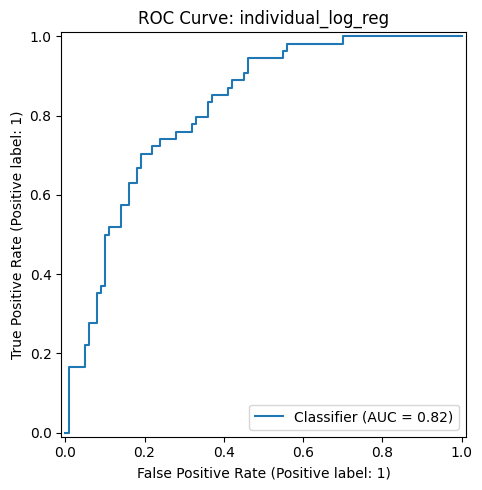

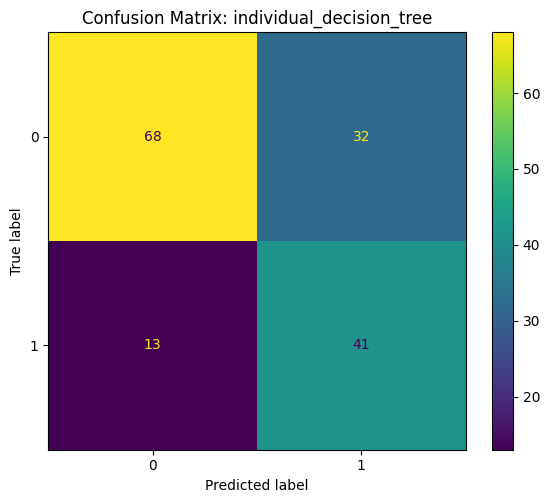

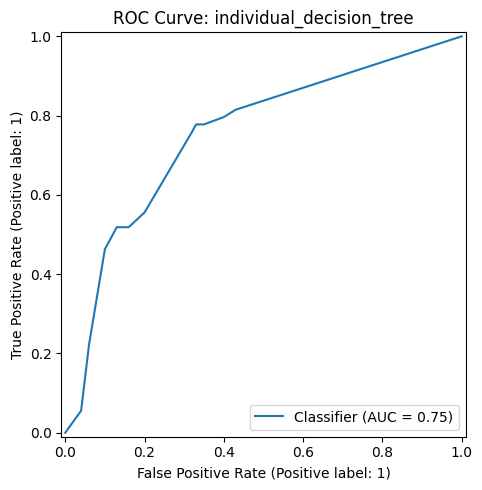

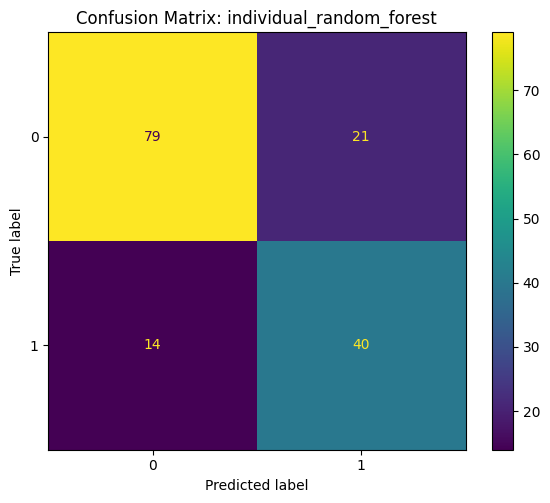

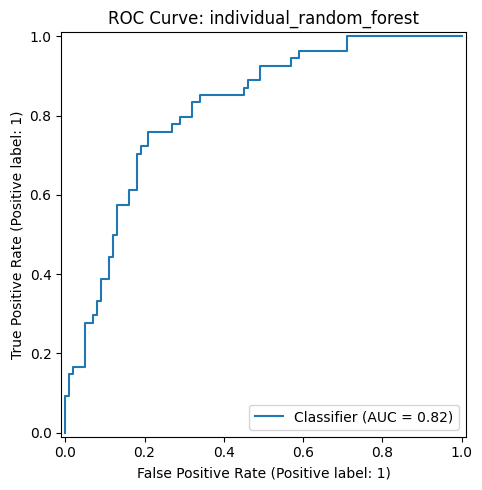

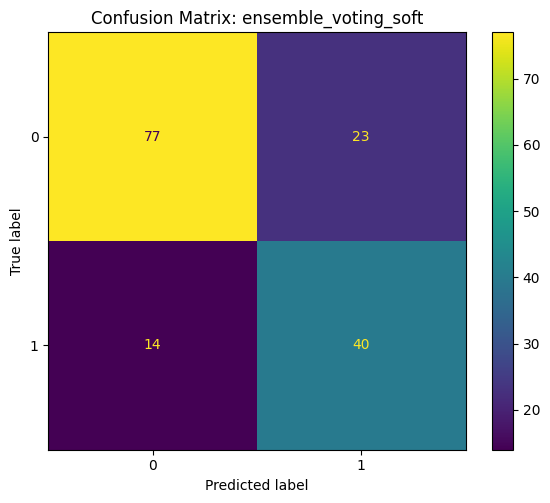

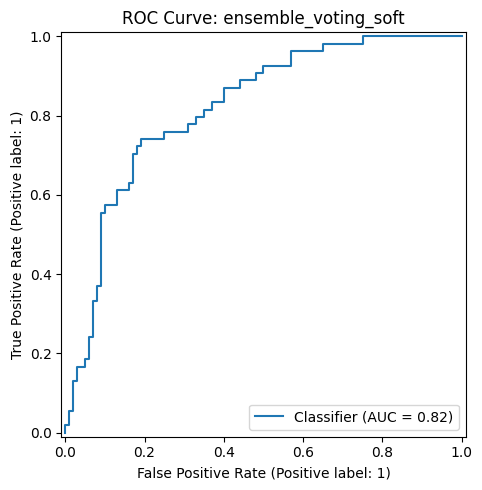

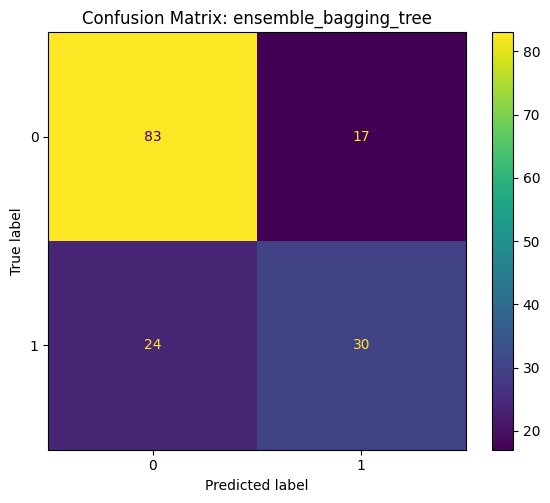

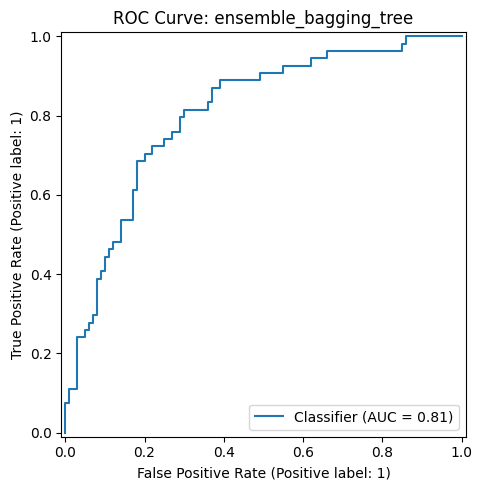

                      model  accuracy  precision    recall        f1   roc_auc
0  individual_random_forest  0.772727   0.655738  0.740741  0.695652  0.816667
1      ensemble_voting_soft  0.759740   0.634921  0.740741  0.683761  0.819630
2        individual_log_reg  0.759740   0.639344  0.722222  0.678261  0.819074
3  individual_decision_tree  0.707792   0.561644  0.759259  0.645669  0.752222
4     ensemble_bagging_tree  0.733766   0.638298  0.555556  0.594059  0.805741

In [94]:
comparison_rows_2 = []
for name, model in trained_models_2.items():
    comparison_rows_2.append(
        evaluate_model(f"individual_{name}", model, X2_test_cluster[feature_cols_2_cluster], y2_test)
    )
for name, model in ensemble_models_2.items():
    comparison_rows_2.append(
        evaluate_model(f"ensemble_{name}", model, X2_test_cluster[feature_cols_2_cluster], y2_test)
    )

comparison_table_2 = pd.DataFrame(comparison_rows_2)[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]]
comparison_table_2 = comparison_table_2.sort_values("f1", ascending=False).reset_index(drop=True)
display(comparison_table_2)


### Dataset 2 — Task 3 Analysis

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest (individual)** | **0.773** | 0.656 | 0.741 | **0.696** | 0.817 |
| Voting Soft (ensemble) | 0.760 | 0.635 | 0.741 | 0.684 | **0.820** |
| Logistic Regression (individual) | 0.760 | 0.639 | 0.722 | 0.678 | 0.819 |
| Bagging (ensemble) | 0.734 | 0.638 | 0.556 | 0.594 | 0.806 |
| Decision Tree (individual) | 0.708 | 0.562 | 0.759 | 0.646 | 0.752 |

- On this much smaller dataset (768 patients total, 614 training rows), the **individual Random Forest is
  the strongest single model** — best accuracy and F1, and close to the top on ROC-AUC.
- Unlike Dataset 1, **the ensembles do not clearly outperform the best individual model here**: Voting
  Soft is essentially tied with Logistic Regression and slightly behind RF on F1, and Bagging actually
  performs *worse* than every individual model except Decision Tree, with its recall dropping to 0.556 —
  likely because with only ~614 training rows, bootstrap-sampled trees see even fewer effective examples
  per tree, which hurts more than it helps at this scale.
- Logistic Regression is competitive here (ROC-AUC 0.819, close to RF's 0.817) — with far fewer
  features and rows than Dataset 1, a simpler linear model is not at a big disadvantage.
- **Takeaway:** ensembling reliably helps on the large, complex Dataset 1 (Bagging's F1 nearly doubles
  the single Decision Tree's), but on the small Dataset 2 the benefit of ensembling is much less clear —
  a well-tuned single Random Forest is competitive with, or better than, both ensembles tested. This
  contrast is itself a useful, real finding to report in Task 6.
